# 03 — Hierarchical Bayesian RAR Model (independent errors, SPARC only)

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

## 1. Research Scope and Modelling Boundaries

This notebook implements the **independent-error** hierarchical model of proposal Sections 4.1–4.2 and the independent-error rungs (a)–(c) of the Section 4.4 error-model ladder, on the **153 eligible SPARC galaxies** (the cross-survey gate did not pass in Notebook 01B).

| In scope | Not in scope (later notebooks) |
|---|---|
| Generalised RAR with free a₀, β | GP radially-correlated covariance J K J (Notebook 04) |
| Within-galaxy scatter σ_int and galaxy-level scatter τ | Population-dependence terms, survey offsets |
| Explicit sampling of D, i, Υ_disk, Υ_bulge per galaxy | Injection–recovery, five-fold cross-validation |
| Models A, B, C of the ladder | Cross-survey inference |

**Model (proposal Sec. 4.1–4.2).** For galaxy *i*, radius *j*: x = log₁₀ g_bar, y = log₁₀ g_obs,

y_ij = f(x_ij; a₀, β) + δ_i + ε_ij, δ_i ~ N(0, τ²), with f from g_obs = g_bar / [1 − exp(−(g_bar/a₀)^β)],

and within-galaxy covariance C_i = Σ_V,i + Σ_x,i(θ) + σ_int² I (no GP term here). δ_i is **marginalised analytically** (adds τ²11ᵀ to C_i), so it is not also sampled; conditional draws of δ_i are produced afterwards for diagnostics.

**Labels used in every table and figure:** `REFERENCE` (published fixed values), `PILOT` (validation on a small deterministic subset; not a scientific result), `FULL` (all 153 galaxies, only if you enable it), `DERIVED` (diagnostics).

## 2. Environment Setup

CPU runtime. The first cell must run **before JAX is imported**: it tells JAX how many CPU devices to expose so that MCMC chains can run in parallel. Double precision (float64) is enabled for numerically stable log-determinants.

In [20]:
import os, sys, importlib.util, subprocess
N_CPU = os.cpu_count() or 1
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={max(1, min(N_CPU, 8))}"
IN_COLAB = "google.colab" in sys.modules
REQUIRED = {"jax": "jax", "numpyro": "numpyro", "xarray": "xarray", "h5netcdf": "h5netcdf", "h5py": "h5py", "scipy": "scipy",
            "matplotlib": "matplotlib", "pandas": "pandas"}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, json, time, hashlib, logging, platform, warnings, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, scipy, scipy.stats as sst, xarray as xr
import matplotlib, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from numpyro.diagnostics import summary as np_summary
numpyro.enable_x64()
numpyro.set_host_device_count(max(1, min(N_CPU, 8)))
try:
    import arviz as az; ARVIZ_VERSION = az.__version__
except Exception:
    az, ARVIZ_VERSION = None, "not installed"

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "jax": jax.__version__, "numpyro": numpyro.__version__, "xarray": xr.__version__, "matplotlib": matplotlib.__version__,
            "arviz": ARVIZ_VERSION, "cpu_count": N_CPU, "jax_devices": len(jax.devices()), "x64": bool(jax.config.read("jax_enable_x64"))}
print(f"Run {RUN_ID} | Colab: {IN_COLAB}"); print(VERSIONS)

Run 20261022T095735Z | Colab: True
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'jax': '0.11.1', 'numpyro': '0.22.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0', 'arviz': '0.22.0', 'cpu_count': 2, 'jax_devices': 2, 'x64': True}


In [21]:
# =====================================================================
# CONFIGURATION — single place for paths, priors and sampler settings
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive"); DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))
ROTMOD_DIR = PROJECT_ROOT / "01_Datasets" / "SPARC" / "Rotmod_LTG"
PROC = PROJECT_ROOT / "03_Processed_Data"
DIRS = {"processed": PROC, "models": PROJECT_ROOT / "04_Trained_Models", "tables": PROJECT_ROOT / "05_Results" / "Tables",
        "graphs": PROJECT_ROOT / "05_Results" / "Graphs", "posterior": PROJECT_ROOT / "05_Results" / "Posterior_Samples",
        "diagnostics": PROJECT_ROOT / "05_Results" / "Diagnostics", "logs": PROC / "logs"}

# Notebook 02 outputs (actual file names written by 02_RAR_Baseline.ipynb)
NB02 = {"points": PROC / "sparc_rar_points_baseline.csv", "galaxies": PROC / "sparc_rar_galaxies_baseline.csv",
        "ref_pars": PROC / "rar_reference_parameters.csv", "binned": PROC / "rar_reference_residuals_binned.csv",
        "exclusions": PROC / "sparc_rar_point_exclusions.csv", "warnings": PROC / "phase1_warning_assessment.csv",
        "checks": PROC / "02_integrity_checks.csv", "manifest": PROC / "02_output_manifest.csv",
        "npz": PROC / "sparc_rar_model_inputs.npz", "npz_meta": PROC / "sparc_rar_model_inputs_metadata.json"}
# Names used in some planning notes; accepted only if the actual names above are absent
NB02_ALTERNATIVE_NAMES = {"exclusions": "rar_reference_point_exclusions.csv", "npz_meta": "rar_model_inputs_metadata.json"}

EXPECTED_N_GALAXIES = int(os.environ.get("RAR_EXPECTED_N_GALAXIES", 153))
EXPECTED_N_POINTS = int(os.environ.get("RAR_EXPECTED_N_POINTS", 3168))

# Units
KPC_IN_M, KMS_IN_MS, LN10 = 3.0856775814913673e19, 1.0e3, float(np.log(10.0))

# REFERENCE values (published; used for initialisation and comparison only, never as results)
REF = {"a0": 1.20e-10, "beta": 0.5, "upsilon_disk": 0.5, "upsilon_bulge": 0.7}

# ---------------- Priors (see Section 8 for justification) ----------------
PRIORS = {
    "log10_a0":      {"dist": "Uniform", "low": -11.5, "high": -8.5, "unit": "log10(m s^-2)", "kind": "computational support (broad)"},
    "beta":          {"dist": "Uniform", "low": 0.05, "high": 1.0, "unit": "-", "kind": "computational support; keeps low-g slope 1-beta in [0, 0.95]"},
    "sigma_int":     {"dist": "HalfNormal", "scale": 0.10, "unit": "dex", "kind": "proposal: half-normal including zero; scale is a regularisation choice"},
    "tau":           {"dist": "HalfNormal", "scale": 0.10, "unit": "dex", "kind": "proposal: half-normal including zero; scale is a regularisation choice"},
    "error_inflation_s": {"dist": "LogNormal", "loc": 0.0, "scale": 0.5, "unit": "-", "kind": "Model B only; regularisation choice (median 1)"},
    "distance":      {"dist": "LogNormal per galaxy", "loc": "ln D_SPARC", "scale": "e_D / D_SPARC", "unit": "Mpc", "kind": "physical: proposal (log-normal, catalogue errors)"},
    "inclination":   {"dist": "TruncatedNormal per galaxy", "loc": "i_SPARC", "scale": "e_i", "low": 1.0, "high": 90.0, "unit": "deg",
                      "kind": "physical: proposal (Gaussian, catalogue errors); bounds 0<i<=90 as in Li et al. 2018"},
    "upsilon_disk":  {"dist": "LogNormal per galaxy", "median": 0.5, "sigma_dex": 0.10, "unit": "Msun/Lsun",
                      "kind": "physical: proposal (log-normal about SPARC value 0.5); 0.1 dex width as in Li et al. 2018, Sec. 2.2"},
    "upsilon_bulge": {"dist": "LogNormal per bulge galaxy", "median": 0.7, "sigma_dex": 0.10, "unit": "Msun/Lsun",
                      "kind": "physical: as above; only galaxies with Vbul > 0 get this parameter"},
}
SIGMA_X_LOG_GBAR = 0.0      # Sigma_x: SPARC files give NO uncertainty on Vgas/Vdisk/Vbul, so this term is zero (documented omission)

# ---------------- Positivity rule for g_bar (Section 6) ----------------
POS_PRIOR_PROB_MIN = 0.999   # a point enters the likelihood only if P_prior(g_bar > 0) >= this value
POS_MC_DRAWS = 200_000

# ---------------- Sampler settings ----------------
SEED = 20261022
TARGET_ACCEPT, MAX_TREE_DEPTH = 0.90, 10
PILOT = {"n_galaxies": int(os.environ.get("RAR_PILOT_NGAL", 12)), "chains": int(os.environ.get("RAR_CHAINS", 4)),
         "warmup": int(os.environ.get("RAR_PILOT_WARMUP", 1000)), "samples": int(os.environ.get("RAR_PILOT_SAMPLES", 1000)), "model": "C"}
FULL_RUN_ENABLED = os.environ.get("RAR_FULL_RUN", "0") == "1"     # <-- set True in Section 13 only after the pilot passes
FULL = {"models": ["C", "A", "B"], "chains": int(os.environ.get("RAR_CHAINS", 4)),
        "warmup": int(os.environ.get("RAR_FULL_WARMUP", 1500)), "samples": int(os.environ.get("RAR_FULL_SAMPLES", 1000))}
FORCE_FULL_DESPITE_PILOT = os.environ.get("RAR_FORCE_FULL", "0") == "1"   # leave False; overriding must be reported
ALLOW_OVERWRITE = False    # if False, an existing output gets a new name with the run ID instead of being replaced

# ---------------- Convergence criteria ----------------
RHAT_MAX = 1.01            # proposal Sec. 4.7
ESS_BULK_MIN = 400         # this notebook's choice (100 per chain for 4 chains)
DIVERGENCES_MAX = 0
PPC_DRAWS = 1000           # posterior draws used for predictive checks
print("Project root:", PROJECT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research


## 3. Google Drive Mounting

In [22]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = DIRS["logs"] / f"03_bayesian_{RUN_ID}.log"
logger = logging.getLogger("rar03"); logger.setLevel(logging.INFO); logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, encoding="utf-8"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    if status == "FAIL":
        raise RuntimeError(f"Critical check failed: {section} | {name} | {detail}")
    return bool(passed)

def safe_path(path: Path) -> Path:
    # Never overwrite a previous result unless ALLOW_OVERWRITE is True.
    if path.exists() and not ALLOW_OVERWRITE:
        new = path.with_name(f"{path.stem}_{RUN_ID}{path.suffix}")
        logger.info(f"{path.name} exists; writing {new.name} instead (ALLOW_OVERWRITE=False)")
        return new
    return path

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Output folders ready; log:", LOG_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output folders ready; log: /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/logs/03_bayesian_20261022T095735Z.log


## 4. Verification of Previous Notebook Outputs

Notebook 02 outputs are verified by **presence, schema, checksums in `02_output_manifest.csv`, and the saved check register**. Nothing is assumed from earlier code.

In [23]:
for k, alt in NB02_ALTERNATIVE_NAMES.items():
    if not NB02[k].is_file() and (PROC / alt).is_file():
        logger.warning(f"Using alternative file name {alt} for {k}"); NB02[k] = PROC / alt
missing = [f"{k}: {p.name}" for k, p in NB02.items() if not p.is_file()]
record_check("Notebook 02", "all expected Notebook 02 files present", not missing, missing or f"{len(NB02)} files")

chk02 = pd.read_csv(NB02["checks"])
n_fail02 = int((chk02.status == "FAIL").sum())
record_check("Notebook 02", "saved 02 check register has no FAIL rows", n_fail02 == 0, f"{len(chk02)} checks, {n_fail02} FAIL, {int((chk02.status=='WARN').sum())} WARN")

man02 = pd.read_csv(NB02["manifest"])
bad = []
for r in man02.itertuples():
    p = PROJECT_ROOT / r.file
    if str(r.sha256).startswith("("):
        continue                                   # log file recorded while open
    if not p.is_file():
        bad.append(f"missing {r.file}")
    elif sha256_of(p) != r.sha256:
        bad.append(f"changed {r.file}")
record_check("Notebook 02", "Notebook 02 outputs match their recorded SHA-256", not bad, bad[:5] or f"{len(man02)} entries checked")

pts = pd.read_csv(NB02["points"]); gals = pd.read_csv(NB02["galaxies"])
REQ_PTS = ["galaxy", "galaxy_index", "point_index", "Rad", "Vobs", "errV", "Vgas", "Vdisk", "Vbul", "distance_mpc", "e_distance_mpc",
           "inc_deg", "e_inc_deg", "g_obs", "g_bar_ref", "included_in_log_analysis", "exclusion_reason"]
REQ_GAL = ["galaxy", "galaxy_index", "n_points_total", "has_bulge", "distance_mpc", "e_distance_mpc", "inc_deg", "e_inc_deg"]
record_check("Notebook 02", "points table has required columns", not [c for c in REQ_PTS if c not in pts], [c for c in REQ_PTS if c not in pts] or "ok")
record_check("Notebook 02", "galaxy table has required columns", not [c for c in REQ_GAL if c not in gals], [c for c in REQ_GAL if c not in gals] or "ok")
record_check("Notebook 02", f"{EXPECTED_N_GALAXIES} galaxies and {EXPECTED_N_POINTS} points",
             pts.galaxy.nunique() == EXPECTED_N_GALAXIES and len(pts) == EXPECTED_N_POINTS, f"{pts.galaxy.nunique()} / {len(pts)}")
record_check("Notebook 02", "galaxy identifiers unique and indices contiguous",
             gals.galaxy.is_unique and sorted(gals.galaxy_index) == list(range(len(gals))), "ok")

npz = np.load(NB02["npz"], allow_pickle=False); meta02 = json.loads(NB02["npz_meta"].read_text())
p_sorted = pts.sort_values(["galaxy_index", "point_index"]).reset_index(drop=True)
same = all(np.array_equal(npz[a], p_sorted[c].to_numpy()) for a, c in
           [("R_kpc", "Rad"), ("Vobs_kms", "Vobs"), ("errV_kms", "errV"), ("Vgas_kms", "Vgas"), ("Vdisk_ups1_kms", "Vdisk"), ("Vbul_ups1_kms", "Vbul")])
record_check("Notebook 02", "model-input arrays (npz) identical to the points table", same and len(npz["R_kpc"]) == len(pts), f"{len(npz['R_kpc'])} rows")
excl02 = pd.read_csv(NB02["exclusions"])
print(f"Notebook 02 reference exclusions ({len(excl02)} rows):"); display(excl02)

INFO: [PASS] Notebook 02 | all expected Notebook 02 files present | 10 files


INFO:rar03:[PASS] Notebook 02 | all expected Notebook 02 files present | 10 files


INFO: [PASS] Notebook 02 | saved 02 check register has no FAIL rows | 36 checks, 0 FAIL, 0 WARN


INFO:rar03:[PASS] Notebook 02 | saved 02 check register has no FAIL rows | 36 checks, 0 FAIL, 0 WARN


INFO: [PASS] Notebook 02 | Notebook 02 outputs match their recorded SHA-256 | 17 entries checked


...

INFO:rar03:[PASS] Notebook 02 | galaxy identifiers unique and indices contiguous | ok


INFO: [PASS] Notebook 02 | model-input arrays (npz) identical to the points table | 3168 rows


INFO:rar03:[PASS] Notebook 02 | model-input arrays (npz) identical to the points table | 3168 rows


Notebook 02 reference exclusions (2 rows):


,galaxy,point_index,Rad,Vobs,errV,Vgas,Vdisk,Vbul,g_bar_ref,exclusion_reason
0,UGC01281,0,0.08,1.41,4.0,-5.85,1.50,0.0,-1.340771e-11,g_bar_ref_nonpositive_(depends_on_Upsilon)
1,UGC01281,1,0.23,4.46,4.0,-5.85,3.55,0.0,-3.934200e-12,g_bar_ref_nonpositive_(depends_on_Upsilon)


## 5. Loading SPARC Model Inputs

The velocities used in the likelihood are re-read from the **original rotmod files** and must equal the Notebook 02 values exactly, so the model uses the original SPARC mass-model components.

In [24]:
def read_rotmod(path):
    lines = path.read_text(encoding="ascii", errors="replace").splitlines()
    hdr = [l.lstrip()[1:].strip() for l in lines if l.lstrip().startswith("#")]
    names = next(h.split() for h in hdr if h.startswith("Rad"))
    rows = [l.split() for l in lines if l.strip() and not l.lstrip().startswith("#")]
    return pd.DataFrame(rows, columns=names).apply(pd.to_numeric, errors="raise")

orig = []
for g in gals.sort_values("galaxy_index").galaxy:
    t = read_rotmod(ROTMOD_DIR / f"{g}_rotmod.dat"); t.insert(0, "galaxy", g); t["point_index"] = np.arange(len(t)); orig.append(t)
orig = pd.concat(orig, ignore_index=True)
m = p_sorted.merge(orig, on=["galaxy", "point_index"], suffixes=("", "_orig"))
maxdiff = max(float(np.max(np.abs(m[c] - m[f"{c}_orig"]))) for c in ["Rad", "Vobs", "errV", "Vgas", "Vdisk", "Vbul"])
record_check("Inputs", "Notebook 02 values identical to original rotmod files", len(m) == len(pts) and maxdiff == 0.0, f"max |diff| {maxdiff}")

G = len(gals)
gi = p_sorted.galaxy_index.to_numpy(np.int32)
gtab = gals.sort_values("galaxy_index").reset_index(drop=True)
has_bulge = p_sorted.groupby("galaxy_index").Vbul.apply(lambda s: bool((s > 0).any())).reindex(range(G)).to_numpy()
record_check("Inputs", "bulge flag agrees with Notebook 02", np.array_equal(has_bulge, gtab.has_bulge.astype(bool).to_numpy()), f"{int(has_bulge.sum())} galaxies with a bulge")
for c in ("e_distance_mpc", "e_inc_deg"):
    record_check("Inputs", f"all {c} > 0 (needed for proper priors)", bool((gtab[c] > 0).all()), f"min {gtab[c].min()}")
print(f"{G} galaxies, {len(p_sorted)} points, {int(has_bulge.sum())} with bulge components")

INFO: [PASS] Inputs | Notebook 02 values identical to original rotmod files | max |diff| 0.0


INFO:rar03:[PASS] Inputs | Notebook 02 values identical to original rotmod files | max |diff| 0.0


INFO: [PASS] Inputs | bulge flag agrees with Notebook 02 | 31 galaxies with a bulge


INFO:rar03:[PASS] Inputs | bulge flag agrees with Notebook 02 | 31 galaxies with a bulge


INFO: [PASS] Inputs | all e_distance_mpc > 0 (needed for proper priors) | min 0.05


INFO:rar03:[PASS] Inputs | all e_distance_mpc > 0 (needed for proper priors) | min 0.05


INFO: [PASS] Inputs | all e_inc_deg > 0 (needed for proper priors) | min 1.0


INFO:rar03:[PASS] Inputs | all e_inc_deg > 0 (needed for proper priors) | min 1.0


153 galaxies, 3168 points, 31 with bulge components


## 6. Physical Units and Nuisance Scaling

At every step the sampled nuisance parameters rescale the **original** quantities (Li et al. 2018, Eqs. 4–5; proposal Sec. 4.2):

* Distance D: R ∝ D; each baryonic velocity component V_k ∝ √D (so V_k² ∝ D); V_obs does not depend on D. Hence **g_bar is independent of D** and **g_obs ∝ 1/D**.
* Inclination i: V_obs and errV both scale by sin(i_SPARC)/sin(i).
* Υ★: V_disk² and V_bul² are tabulated for Υ = 1 and are multiplied by Υ_disk and Υ_bulge. V_gas keeps its SPARC sign convention, entering as V_gas·|V_gas|.
* Units: g = V² / R with V in m s⁻¹ and R in m, giving m s⁻².

**Positivity rule (non-positive g_bar).** f(x) needs g_bar > 0, and the sign of g_bar depends only on Υ★ (D cancels). For each point, P_prior(g_bar > 0) is computed under the Υ★ priors by Monte Carlo. A point enters the likelihood if this probability is ≥ 0.999. Points below that are excluded **before** inference and reported with the Υ★ value they would need. This is a fixed data-domain rule, not a parameter-dependent one. Inside the sampler, any configuration giving g_bar ≤ 0 at an included point has zero likelihood (log-likelihood = −∞), using a NaN-safe implementation.

In [25]:
R0, V0, eV0 = npz["R_kpc"], npz["Vobs_kms"], npz["errV_kms"]
Vg0, Vd0, Vb0 = npz["Vgas_kms"], npz["Vdisk_ups1_kms"], npz["Vbul_ups1_kms"]
D0, eD0 = gtab.distance_mpc.to_numpy(float), gtab.e_distance_mpc.to_numpy(float)
I0, eI0 = gtab.inc_deg.to_numpy(float), gtab.e_inc_deg.to_numpy(float)

def accelerations(D, inc_deg, ups_d, ups_b, idx, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=jnp):
    # Returns g_obs, g_bar (m s^-2) and sigma_V in dex for nuisance values (per galaxy arrays).
    sD = (D / D0)[idx]
    s_inc = (xp.sin(xp.deg2rad(I0)) / xp.sin(xp.deg2rad(inc_deg)))[idx]
    R_m = R0 * sD * KPC_IN_M
    Vobs, eV = V0 * s_inc, eV0 * s_inc
    vbar2 = (Vg0 * xp.abs(Vg0) + ups_d[idx] * Vd0 ** 2 + ups_b[idx] * Vb0 ** 2) * sD       # (km/s)^2
    g_obs = (Vobs * KMS_IN_MS) ** 2 / R_m
    g_bar = vbar2 * KMS_IN_MS ** 2 / R_m
    sig_V = 2.0 * eV / (Vobs * LN10)
    return g_obs, g_bar, sig_V

# Tests of the transformations (NumPy)
ref_ud, ref_ub = np.full(G, REF["upsilon_disk"]), np.full(G, REF["upsilon_bulge"])
go, gb, sv = accelerations(D0, I0, ref_ud, ref_ub, gi, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=np)
record_check("Scaling", "catalogue nuisance values reproduce Notebook 02 g_obs and g_bar",
             np.allclose(go, p_sorted.g_obs, rtol=1e-12) and np.allclose(gb, p_sorted.g_bar_ref, rtol=1e-12, atol=1e-30), "ok")
go2, gb2, sv2 = accelerations(D0 * 1.3, I0, ref_ud, ref_ub, gi, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=np)
record_check("Scaling", "g_bar independent of D, g_obs ∝ 1/D, sigma_V independent of D",
             np.allclose(gb2, gb, rtol=1e-12) and np.allclose(go2 * 1.3, go, rtol=1e-12) and np.allclose(sv2, sv), "D x 1.3")
inc_t = np.clip(I0 - 5.0, 1.0, 90.0)
go3, _, sv3 = accelerations(D0, inc_t, ref_ud, ref_ub, gi, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=np)
expect = go * (np.sin(np.deg2rad(I0)) / np.sin(np.deg2rad(inc_t)))[gi] ** 2
record_check("Scaling", "g_obs ∝ (sin i_SPARC / sin i)^2 and sigma_V invariant to i", np.allclose(go3, expect, rtol=1e-12) and np.allclose(sv3, sv), "i - 5 deg")
ext = accelerations(D0 * 3, np.full(G, 1.0), ref_ud * 10, ref_ub * 10, gi, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=np)
record_check("Scaling", "extreme nuisance values give finite accelerations", all(np.isfinite(a).all() for a in ext), "D x3, i = 1 deg, Y x10")
record_check("Units", "100 km/s at 1 kpc = 3.2408e-10 m s^-2", abs((1e5) ** 2 / KPC_IN_M / 3.2408e-10 - 1) < 1e-4, "ok")

# Positivity rule: P_prior(g_bar > 0) per point (sign depends only on Upsilon)
rng = np.random.default_rng(SEED)
ud_draw = 10 ** (np.log10(PRIORS["upsilon_disk"]["median"]) + PRIORS["upsilon_disk"]["sigma_dex"] * rng.standard_normal(POS_MC_DRAWS))
ub_draw = 10 ** (np.log10(PRIORS["upsilon_bulge"]["median"]) + PRIORS["upsilon_bulge"]["sigma_dex"] * rng.standard_normal(POS_MC_DRAWS))
p_pos = np.ones(len(R0)); ups_needed = np.full(len(R0), np.nan)
for k in np.where(Vg0 <= 0)[0]:
    num = ud_draw * Vd0[k] ** 2 + ub_draw * Vb0[k] ** 2 + Vg0[k] * abs(Vg0[k])
    p_pos[k] = float(np.mean(num > 0))
    if Vd0[k] > 0 and Vb0[k] == 0:
        ups_needed[k] = Vg0[k] ** 2 / Vd0[k] ** 2
include = p_pos >= POS_PRIOR_PROB_MIN
include &= gb > 0                                           # same point set for Models A/B (reference Upsilon) and C
pos_table = p_sorted.loc[~include | (p_pos < 1), ["galaxy", "point_index", "Rad", "Vgas", "Vdisk", "Vbul", "g_bar_ref"]].copy()
pos_table["P_prior_gbar_positive"] = p_pos[pos_table.index]
pos_table["Upsilon_disk_needed_if_no_bulge"] = ups_needed[pos_table.index]
pos_table["included_in_likelihood"] = include[pos_table.index]
print(f"Points entering the likelihood: {int(include.sum())} of {len(include)}; excluded by the positivity rule: {int((~include).sum())}")
display(pos_table)
ref_excl_keys = set(zip(excl02.galaxy, excl02.point_index)) if "point_index" in excl02 else set()
rule_excl_keys = set(zip(p_sorted.galaxy[~include], p_sorted.point_index[~include]))
record_check("Positivity", "every point excluded by the rule was also non-positive at reference Upsilon (no new exclusions)",
             rule_excl_keys <= ref_excl_keys or not ref_excl_keys, f"rule excludes {sorted(rule_excl_keys)}", severity="warning")
record_check("Positivity", "no galaxy loses all its points", set(range(G)) == set(gi[include]), "ok")

INFO: [PASS] Scaling | catalogue nuisance values reproduce Notebook 02 g_obs and g_bar | ok


INFO:rar03:[PASS] Scaling | catalogue nuisance values reproduce Notebook 02 g_obs and g_bar | ok


INFO: [PASS] Scaling | g_bar independent of D, g_obs ∝ 1/D, sigma_V independent of D | D x 1.3


INFO:rar03:[PASS] Scaling | g_bar independent of D, g_obs ∝ 1/D, sigma_V independent of D | D x 1.3


INFO: [PASS] Scaling | g_obs ∝ (sin i_SPARC / sin i)^2 and sigma_V invariant to i | i - 5 deg


...

Points entering the likelihood: 3164 of 3168; excluded by the positivity rule: 4


,galaxy,point_index,Rad,Vgas,Vdisk,Vbul,g_bar_ref,P_prior_gbar_positive,Upsilon_disk_needed_if_no_bulge,included_in_likelihood
35,DDO064,0,0.10,-1.13,1.96,0.0,2.086738e-13,0.962405,0.332388,False
1792,UGC01281,0,0.08,-5.85,1.50,0.0,-1.340771e-11,0.000000,15.210000,False
1793,UGC01281,1,0.23,-5.85,3.55,0.0,-3.934200e-12,0.000000,2.715533,False
2695,UGC07577,0,0.19,-1.81,3.43,0.0,4.445582e-13,0.994535,0.278464,False


INFO: [PASS] Positivity | no galaxy loses all its points | ok


INFO:rar03:[PASS] Positivity | no galaxy loses all its points | ok


True

## 7. Generalised RAR Implementation

f(x) = x − log₁₀[1 − exp(−t)], with t = (g_bar/a₀)^β computed in log space and `expm1` for stability. The local slope f′(x) = 1 − β·t·e^(−t)/(1 − e^(−t)) is needed for the Σ_x term. It is implemented analytically and checked against automatic differentiation.

In [26]:
def f_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return x - jnp.log10(-jnp.expm1(-t))

def fprime_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return 1.0 - beta * t * jnp.exp(-t) / (-jnp.expm1(-t))

# Tests against the Notebook 02 reference definition and analytic limits
xs = jnp.linspace(-14.0, -7.0, 300); la0 = np.log10(REF["a0"])
g = 10 ** np.asarray(xs); ref_np = np.log10(g / (1 - np.exp(-(g / REF["a0"]) ** 0.5)))
record_check("RAR", "f matches the Notebook 02 reference form (beta = 0.5)", np.allclose(f_rar(xs, la0, 0.5), ref_np, atol=1e-12), "ok")
record_check("RAR", "high-g limit f(x) -> x", abs(float(f_rar(-7.0, la0, 0.5)) + 7.0) < 1e-6, "ok")
record_check("RAR", "low-g slope -> 1 - beta (beta = 0.3)", abs(float(fprime_rar(-25.0, la0, 0.3)) - 0.7) < 1e-3, "ok")
ad = jax.vmap(jax.grad(f_rar), in_axes=(0, None, None))(xs, la0, 0.4)
record_check("RAR", "analytic f' equals autodiff f'", np.allclose(ad, fprime_rar(xs, la0, 0.4), atol=1e-10), "ok")
record_check("RAR", "f monotonic and finite on [-14, -7]", bool(jnp.all(jnp.diff(f_rar(xs, la0, 0.5)) > 0) & jnp.all(jnp.isfinite(f_rar(xs, la0, 0.5)))), "ok")

INFO: [PASS] RAR | f matches the Notebook 02 reference form (beta = 0.5) | ok


INFO:rar03:[PASS] RAR | f matches the Notebook 02 reference form (beta = 0.5) | ok


INFO: [PASS] RAR | high-g limit f(x) -> x | ok


INFO:rar03:[PASS] RAR | high-g limit f(x) -> x | ok


INFO: [PASS] RAR | low-g slope -> 1 - beta (beta = 0.3) | ok


...

INFO: [PASS] RAR | analytic f' equals autodiff f' | ok


INFO:rar03:[PASS] RAR | analytic f' equals autodiff f' | ok


INFO: [PASS] RAR | f monotonic and finite on [-14, -7] | ok


INFO:rar03:[PASS] RAR | f monotonic and finite on [-14, -7] | ok


True

## 8. Prior Specification

| Parameter | Prior | Type |
|---|---|---|
| log₁₀ a₀ | Uniform(−11.5, −8.5) | computational support, broad |
| β | Uniform(0.05, 1.0) | computational support |
| σ_int, τ | HalfNormal(0.1 dex) | proposal requires priors that include zero; the 0.1 dex scale is a regularisation choice |
| s (Model B only) | LogNormal(0, 0.5) | regularisation choice |
| D_i | LogNormal(ln D_SPARC, e_D/D_SPARC) | physical (proposal; catalogue errors) |
| i_i | TruncatedNormal(i_SPARC, e_i; 1°, 90°) | physical (proposal; bounds as in Li et al. 2018) |
| Υ_disk,i | log₁₀ Υ ~ N(log₁₀ 0.5, 0.1) | physical (proposal; 0.1 dex width as used by Li et al. 2018 Sec. 2.2) |
| Υ_bulge,i | log₁₀ Υ ~ N(log₁₀ 0.7, 0.1) for galaxies with V_bul > 0 only | physical (as above) |

Non-centred forms are used for D and Υ★ (z ~ N(0,1)), which helps NUTS. Galaxies without a bulge get **no** bulge parameter.

In [27]:
prior_rows = [{"parameter": k, **{kk: str(vv) for kk, vv in v.items()}} for k, v in PRIORS.items()]
prior_rows.append({"parameter": "Sigma_x (log g_bar uncertainty)", "dist": "fixed 0", "unit": "dex",
                   "kind": "documented omission: SPARC gives no Vgas/Vdisk/Vbul uncertainties; structure retained (SIGMA_X_LOG_GBAR)"})
prior_summary = pd.DataFrame(prior_rows)
display(prior_summary)

,parameter,dist,low,high,unit,kind,scale,loc,median,sigma_dex
0,log10_a0,Uniform,-11.5,-8.5,log10(m s^-2),computational support (broad),NaN,NaN,NaN,NaN
1,beta,Uniform,0.05,1.0,-,computational support; keeps low-g slope 1-bet...,NaN,NaN,NaN,NaN
2,sigma_int,HalfNormal,NaN,NaN,dex,proposal: half-normal including zero; scale is...,0.1,NaN,NaN,NaN
3,tau,HalfNormal,NaN,NaN,dex,proposal: half-normal including zero; scale is...,0.1,NaN,NaN,NaN
4,error_inflation_s,LogNormal,NaN,NaN,-,Model B only; regularisation choice (median 1),0.5,0.0,NaN,NaN
5,distance,LogNormal per galaxy,NaN,NaN,Mpc,"physical: proposal (log-normal, catalogue errors)",e_D / D_SPARC,ln D_SPARC,NaN,NaN
6,inclination,TruncatedNormal per galaxy,1.0,90.0,deg,"physical: proposal (Gaussian, catalogue errors...",e_i,i_SPARC,NaN,NaN
7,upsilon_disk,LogNormal per galaxy,NaN,NaN,Msun/Lsun,physical: proposal (log-normal about SPARC val...,NaN,NaN,0.5,0.1
8,upsilon_bulge,LogNormal per bulge galaxy,NaN,NaN,Msun/Lsun,physical: as above; only galaxies with Vbul > ...,NaN,NaN,0.7,0.1
9,Sigma_x (log g_bar uncertainty),fixed 0,NaN,NaN,dex,documented omission: SPARC gives no Vgas/Vdisk...,NaN,NaN,NaN,NaN


## 9. Hierarchical Bayesian Likelihood

For galaxy *i* with residuals r = y − f(x) and diagonal d_j = s²σ_V,j² + f′(x_j)²σ_x,j² + σ_int², the covariance is C = diag(d) + τ²11ᵀ. Using the Sherman–Morrison identity:

* log det C = Σ log d_j + log(1 + τ²S), with S = Σ 1/d_j
* rᵀC⁻¹r = Σ r_j²/d_j − τ²(Σ r_j/d_j)² / (1 + τ²S)
* ln L_i = −½ [rᵀC⁻¹r + log det C + n_i ln 2π]

This is exact (no approximation) and O(n). C is positive-definite whenever every d_j > 0, which holds because σ_V > 0. **Models:** A = catalogue nuisance values fixed and published errors (s = 1); B = as A with a free error-inflation factor s; C = nuisance parameters sampled (s = 1).

In [28]:
def build_data(mask_points, galaxy_subset=None):
    sel = np.asarray(mask_points, bool).copy()
    if galaxy_subset is not None:
        sel &= np.isin(gi, galaxy_subset)
    gal_ids = np.unique(gi[sel]); remap = -np.ones(G, int); remap[gal_ids] = np.arange(len(gal_ids))
    bulge_gals = np.where(has_bulge[gal_ids])[0]
    return {"idx": jnp.asarray(remap[gi[sel]]), "G": len(gal_ids), "gal_ids": gal_ids, "bulge_local": jnp.asarray(bulge_gals),
            "n_bulge": len(bulge_gals), "point_rows": np.where(sel)[0],
            **{k: jnp.asarray(v[sel]) for k, v in dict(R0=R0, V0=V0, eV0=eV0, Vg0=Vg0, Vd0=Vd0, Vb0=Vb0).items()},
            "D0": jnp.asarray(D0[gal_ids]), "eD0": jnp.asarray(eD0[gal_ids]), "I0": jnp.asarray(I0[gal_ids]), "eI0": jnp.asarray(eI0[gal_ids]),
            "sigx": jnp.full(int(sel.sum()), SIGMA_X_LOG_GBAR)}

def galaxy_loglik(params, data, nuis):
    # Exact marginal log-likelihood per galaxy (delta_i integrated out). Returns (ll_g, all_positive).
    log10_a0, beta, sig_int, tau, s = params
    D, inc, ud, ub = nuis
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, data["idx"], data["R0"], data["V0"], data["eV0"],
                                        data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10))                   # NaN-safe; masked below
    y = jnp.log10(g_obs)
    r = y - f_rar(x, log10_a0, beta)
    d = (s * sig_V) ** 2 + (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2 + sig_int ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    quad = Q - tau ** 2 * A ** 2 / (1 + tau ** 2 * S)
    logdet = L + jnp.log1p(tau ** 2 * S)
    ll = -0.5 * (quad + logdet + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

def nuisance_fixed(data):
    return (data["D0"], data["I0"], jnp.full(data["G"], REF["upsilon_disk"]), jnp.full(data["G"], REF["upsilon_bulge"]))

def rar_model(data, model="C"):
    log10_a0 = numpyro.sample("log10_a0", dist.Uniform(PRIORS["log10_a0"]["low"], PRIORS["log10_a0"]["high"]))
    beta = numpyro.sample("beta", dist.Uniform(PRIORS["beta"]["low"], PRIORS["beta"]["high"]))
    sig_int = numpyro.sample("sigma_int", dist.HalfNormal(PRIORS["sigma_int"]["scale"]))
    tau = numpyro.sample("tau", dist.HalfNormal(PRIORS["tau"]["scale"]))
    s = numpyro.sample("s", dist.LogNormal(PRIORS["error_inflation_s"]["loc"], PRIORS["error_inflation_s"]["scale"])) if model == "B" else 1.0
    if model == "C":
        with numpyro.plate("galaxies", data["G"]):
            zD = numpyro.sample("zD", dist.Normal(0, 1))
            inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=PRIORS["inclination"]["low"], high=PRIORS["inclination"]["high"]))
            zUd = numpyro.sample("zUd", dist.Normal(0, 1))
        D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
        ud = numpyro.deterministic("ups_disk", PRIORS["upsilon_disk"]["median"] * 10 ** (PRIORS["upsilon_disk"]["sigma_dex"] * zUd))
        ub = jnp.full(data["G"], REF["upsilon_bulge"])           # placeholder only; multiplied by Vbul = 0 where no bulge
        if data["n_bulge"] > 0:
            with numpyro.plate("bulge_galaxies", data["n_bulge"]):
                zUb = numpyro.sample("zUb", dist.Normal(0, 1))
            ub = ub.at[data["bulge_local"]].set(PRIORS["upsilon_bulge"]["median"] * 10 ** (PRIORS["upsilon_bulge"]["sigma_dex"] * zUb))
            numpyro.deterministic("ups_bulge", ub[data["bulge_local"]])
        nuis = (D, inc, ud, ub)
    else:
        nuis = nuisance_fixed(data)
    numpyro.deterministic("a0", 10 ** log10_a0)
    ll, ok = galaxy_loglik((log10_a0, beta, sig_int, tau, s), data, nuis)
    numpyro.factor("loglik", jnp.where(ok, jnp.sum(ll), -jnp.inf))

## 10. Likelihood and Numerical Integrity Tests

The fast likelihood is compared with a direct dense multivariate-normal evaluation (SciPy). The tests also check positive-definiteness, finiteness and gradients at the starting point, and that the model's total log-density is finite.

In [29]:
data_all = build_data(include)
fixed = nuisance_fixed(data_all)
test_params = [(np.log10(REF["a0"]), 0.5, 0.05, 0.07, 1.0), (-10.2, 0.62, 0.11, 0.02, 1.3)]
for tp in test_params:
    ll, ok = galaxy_loglik(tp, data_all, fixed)
    go_, gb_, sv_ = accelerations(*fixed, data_all["idx"], data_all["R0"], data_all["V0"], data_all["eV0"], data_all["Vg0"],
                                  data_all["Vd0"], data_all["Vb0"], data_all["D0"], data_all["I0"], xp=jnp)
    x_, y_ = np.log10(np.asarray(gb_)), np.log10(np.asarray(go_)); idx_ = np.asarray(data_all["idx"])
    for gg in [0, data_all["G"] // 2, data_all["G"] - 1]:
        mk = idx_ == gg
        r_ = y_[mk] - np.asarray(f_rar(x_[mk], tp[0], tp[1]))
        dd = (tp[4] * np.asarray(sv_)[mk]) ** 2 + tp[2] ** 2
        C = np.diag(dd) + tp[3] ** 2 * np.ones((mk.sum(), mk.sum()))
        dense = sst.multivariate_normal(mean=np.zeros(mk.sum()), cov=C).logpdf(r_)
        record_check("Likelihood", f"Sherman–Morrison = dense MVN (galaxy {gg}, params {tp[:4]})", abs(float(ll[gg]) - dense) < 1e-8 * max(1, abs(dense)), f"{float(ll[gg]):.6f} vs {dense:.6f}")
        record_check("Likelihood", f"covariance positive-definite (galaxy {gg})", bool(np.linalg.eigvalsh(C).min() > 0), f"min eig {np.linalg.eigvalsh(C).min():.2e}")
    record_check("Likelihood", f"all galaxy log-likelihoods finite at {tp[:4]}", bool(ok) and bool(jnp.all(jnp.isfinite(ll))), f"sum {float(jnp.sum(ll)):.2f}")

def init_values(data, model):
    v = {"log10_a0": np.log10(REF["a0"]), "beta": REF["beta"], "sigma_int": 0.05, "tau": 0.05}
    if model == "B": v["s"] = 1.0
    if model == "C":
        v.update({"zD": jnp.zeros(data["G"]), "inc": jnp.clip(data["I0"], 2.0, 89.5), "zUd": jnp.zeros(data["G"])})
        if data["n_bulge"]: v["zUb"] = jnp.zeros(data["n_bulge"])
    return v

from numpyro.infer.util import log_density
for model in ("A", "B", "C"):
    iv = init_values(data_all, model)
    lp, _ = log_density(rar_model, (data_all, model), {}, iv)
    grads = jax.grad(lambda p: log_density(rar_model, (data_all, model), {}, p)[0])(iv)
    gfin = all(bool(jnp.all(jnp.isfinite(v))) for v in jax.tree_util.tree_leaves(grads))
    record_check("Likelihood", f"Model {model}: finite log-density and gradient at initial values", bool(jnp.isfinite(lp)) and gfin, f"log p = {float(lp):.2f}")

INFO: [PASS] Likelihood | Sherman–Morrison = dense MVN (galaxy 0, params (np.float64(-9.920818753952375), 0.5, 0.05, 0.07)) | -38.040159 vs -38.040159


INFO:rar03:[PASS] Likelihood | Sherman–Morrison = dense MVN (galaxy 0, params (np.float64(-9.920818753952375), 0.5, 0.05, 0.07)) | -38.040159 vs -38.040159


INFO: [PASS] Likelihood | covariance positive-definite (galaxy 0) | min eig 7.28e-03


INFO:rar03:[PASS] Likelihood | covariance positive-definite (galaxy 0) | min eig 7.28e-03


INFO: [PASS] Likelihood | Sherman–Morrison = dense MVN (galaxy 76, params (np.float64(-9.920818753952375), 0.5, 0.05, 0.07)) | 55.834947 vs 55.834947


...

INFO:rar03:[PASS] Likelihood | Model A: finite log-density and gradient at initial values | log p = 2804.47


INFO: [PASS] Likelihood | Model B: finite log-density and gradient at initial values | log p = 2804.24


INFO:rar03:[PASS] Likelihood | Model B: finite log-density and gradient at initial values | log p = 2804.24


INFO: [PASS] Likelihood | Model C: finite log-density and gradient at initial values | log p = 2165.65


INFO:rar03:[PASS] Likelihood | Model C: finite log-density and gradient at initial values | log p = 2165.65


### Shared sampling, diagnostic and saving utilities

In [30]:
from jax.scipy.special import logsumexp as jlogsumexp

def run_mcmc(data, model, chains, warmup, samples, seed):
    kernel = NUTS(rar_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH,
                  init_strategy=init_to_value(values=init_values(data, model)))
    method = "parallel" if len(jax.devices()) >= chains else "sequential"
    mcmc = MCMC(kernel, num_warmup=warmup, num_samples=samples, num_chains=chains, chain_method=method, progress_bar=True)
    t0 = time.time()
    mcmc.run(jax.random.PRNGKey(seed), data, model, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    return mcmc, time.time() - t0, method

GLOBALS = ["log10_a0", "beta", "sigma_int", "tau", "s"]

def diagnostics(mcmc, data, model):
    smp = mcmc.get_samples(group_by_chain=True)
    keep = {k: v for k, v in smp.items() if k in GLOBALS + ["zD", "inc", "zUd", "zUb"]}
    summ = np_summary({k: np.asarray(v) for k, v in keep.items()}, prob=0.68)
    rows = []
    for k, st in summ.items():
        r_hat = np.atleast_1d(st["r_hat"]); ess = np.atleast_1d(st["n_eff"])
        rows.append({"parameter": k, "n_elements": r_hat.size, "max_r_hat": float(np.nanmax(r_hat)),
                     "min_ess_bulk": float(np.nanmin(ess)), "median_ess": float(np.nanmedian(ess))})
    diag = pd.DataFrame(rows)
    ex = mcmc.get_extra_fields(group_by_chain=True)
    div = np.asarray(ex["diverging"]); steps = np.asarray(ex["num_steps"]); energy = np.asarray(ex["energy"])
    bfmi = [float(np.mean(np.diff(e) ** 2) / np.var(e)) for e in energy]
    stats = {"divergences": int(div.sum()), "divergences_per_chain": div.sum(axis=1).tolist(),
             "max_tree_depth_hits": int((steps >= 2 ** MAX_TREE_DEPTH - 1).sum()), "bfmi_per_chain": bfmi,
             "mean_accept_prob": float(np.mean(np.asarray(ex["accept_prob"])))}
    converged = (diag.max_r_hat.max() < RHAT_MAX) and (diag.min_ess_bulk.min() >= ESS_BULK_MIN) and (stats["divergences"] <= DIVERGENCES_MAX)
    stats.update({"max_r_hat_all": float(diag.max_r_hat.max()), "min_ess_bulk_all": float(diag.min_ess_bulk.min()),
                  "converged_by_all_criteria": bool(converged)})
    return diag, stats

def posterior_table(mcmc, label):
    smp = mcmc.get_samples()
    rows = []
    for k in GLOBALS + ["a0"]:
        if k not in smp: continue
        v = np.asarray(smp[k]); q = np.percentile(v, [2.5, 16, 50, 84, 97.5])
        rows.append({"stage": label, "parameter": k, "mean": v.mean(), "median": q[2], "sd": v.std(ddof=1),
                     "ci68_low": q[1], "ci68_high": q[3], "ci95_low": q[0], "ci95_high": q[4]})
    for k in ("sigma_int", "tau"):
        if k in smp:
            rows.append({"stage": label, "parameter": f"{k}_95pct_upper_limit", "median": float(np.percentile(np.asarray(smp[k]), 95))})
    return pd.DataFrame(rows)

def per_draw_nuisance(smp, data, model, i):
    if model != "C":
        return nuisance_fixed(data)
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(smp["ups_bulge"][i])
    return (smp["D"][i], smp["inc"][i], smp["ups_disk"][i], ub)

def draw_quantities(smp, data, model, i, key):
    # Per-draw: galaxy log-lik, x, y, mean prediction, conditional delta draw and replicated y.
    s = smp["s"][i] if "s" in smp else 1.0
    th = (smp["log10_a0"][i], smp["beta"][i], smp["sigma_int"][i], smp["tau"][i], s)
    nuis = per_draw_nuisance(smp, data, model, i)
    ll, ok = galaxy_loglik(th, data, nuis)
    g_obs, g_bar, sig_V = accelerations(*nuis, data["idx"], data["R0"], data["V0"], data["eV0"], data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    x = jnp.log10(jnp.where(g_bar > 0, g_bar, 1e-10)); y = jnp.log10(g_obs); mu = f_rar(x, th[0], th[1])
    d = (s * sig_V) ** 2 + (fprime_rar(x, th[0], th[1]) * data["sigx"]) ** 2 + th[2] ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    prec = 1 / th[3] ** 2 + seg(1 / d); mean = seg((y - mu) / d) / prec      # delta_i | data, theta
    k1, k2 = jax.random.split(key)
    delta = mean + jax.random.normal(k1, (data["G"],)) / jnp.sqrt(prec)
    yrep = mu + delta[data["idx"]] + jnp.sqrt(d) * jax.random.normal(k2, d.shape)
    return ll, x, y, mu, delta, yrep, jnp.sqrt(d)

def posterior_draw_products(mcmc, data, model, n_draws, seed):
    smp = {k: jnp.asarray(v) for k, v in mcmc.get_samples().items()}
    N = len(smp["log10_a0"]); sel = np.linspace(0, N - 1, min(n_draws, N)).astype(int)
    keys = jax.random.split(jax.random.PRNGKey(seed + 1), len(sel))
    f = jax.jit(lambda i, k: draw_quantities(smp, data, model, i, k))
    outs = [f(int(i), k) for i, k in zip(sel, keys)]
    stack = lambda j: np.stack([np.asarray(o[j]) for o in outs])
    return {"draw_index": sel, "ll_g": stack(0), "x": stack(1), "y": stack(2), "mu": stack(3), "delta": stack(4), "yrep": stack(5), "sd": stack(6)}

def galaxy_loglik_all_draws(mcmc, data, model):
    smp = {k: jnp.asarray(v) for k, v in mcmc.get_samples().items()}
    N = len(smp["log10_a0"])
    f = jax.jit(jax.vmap(lambda i: draw_quantities(smp, data, model, i, jax.random.PRNGKey(0))[0]))
    out = np.concatenate([np.asarray(f(jnp.arange(a, min(a + 250, N)))) for a in range(0, N, 250)])
    return out    # (draws, galaxies)

def save_posterior_netcdf(mcmc, data, model, path, ll_g):
    # ArviZ-compatible InferenceData layout (groups: posterior, sample_stats, log_likelihood) written with xarray/h5netcdf.
    smp = mcmc.get_samples(group_by_chain=True); ex = mcmc.get_extra_fields(group_by_chain=True)
    C_, S_ = np.asarray(smp["log10_a0"]).shape
    gal_names = gtab.galaxy.to_numpy()[data["gal_ids"]]
    bulge_names = gal_names[np.asarray(data["bulge_local"])] if data["n_bulge"] else np.array([], str)
    post = {}
    for k, v in smp.items():
        v = np.asarray(v)
        if v.ndim == 2: post[k] = (("chain", "draw"), v)
        elif k == "ups_bulge" or k == "zUb": post[k] = (("chain", "draw", "bulge_galaxy"), v)
        else: post[k] = (("chain", "draw", "galaxy"), v)
    coords = {"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": gal_names.astype(str)}
    if data["n_bulge"]: coords["bulge_galaxy"] = bulge_names.astype(str)
    ds_post = xr.Dataset(post, coords=coords, attrs={"model": model, "run_id": RUN_ID, "created": RUN_TIMESTAMP})
    ds_ss = xr.Dataset({"diverging": (("chain", "draw"), np.asarray(ex["diverging"])), "n_steps": (("chain", "draw"), np.asarray(ex["num_steps"])),
                        "energy": (("chain", "draw"), np.asarray(ex["energy"])), "acceptance_rate": (("chain", "draw"), np.asarray(ex["accept_prob"]))},
                       coords={"chain": np.arange(C_), "draw": np.arange(S_)})
    ds_ll = xr.Dataset({"galaxy_loglik": (("chain", "draw", "galaxy"), ll_g.reshape(C_, S_, -1))},
                       coords={"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": gal_names.astype(str)})
    path = safe_path(path)
    ds_post.to_netcdf(path, group="posterior", mode="w", engine="h5netcdf")
    ds_ss.to_netcdf(path, group="sample_stats", mode="a", engine="h5netcdf")
    ds_ll.to_netcdf(path, group="log_likelihood", mode="a", engine="h5netcdf")
    return path

# ---- Galaxy-level PSIS-LOO (Vehtari, Gelman & Gabry 2017), implemented here to avoid ArviZ version differences ----
def _gpdfit(x):
    n = len(x); prior_bs, prior_k = 3, 10
    m = 30 + int(np.sqrt(n))
    bs = 1 - np.sqrt(m / (np.arange(1, m + 1) - 0.5))
    bs /= prior_bs * x[int(n / 4 + 0.5) - 1]
    bs += 1 / x[-1]
    ks = np.log1p(-bs[:, None] * x).mean(axis=1)
    L = n * (np.log(-(bs / ks)) - ks - 1)
    w = 1 / np.exp(L - L[:, None]).sum(axis=1)
    w /= w.sum()
    b = np.sum(bs * w)
    k = np.log1p(-b * x).mean()
    sigma = -k / b
    k = (n * k + prior_k * 0.5) / (n + prior_k)
    return k, sigma

def psis_loo(ll):
    # ll: (draws, units). Returns elpd_loo per unit and Pareto k per unit.
    S, U = ll.shape; elpd = np.empty(U); khat = np.empty(U)
    M = int(np.ceil(min(0.2 * S, 3 * np.sqrt(S))))
    for u in range(U):
        lw = -ll[:, u].astype(float); lw = lw - lw.max()
        order = np.argsort(lw); tail = order[-M:]
        cutoff = lw[order[-M - 1]]
        x = np.exp(lw[tail]) - np.exp(cutoff)
        if np.all(x > 0) and M >= 5:
            k, sig = _gpdfit(np.sort(x))
            p = (np.arange(M) + 0.5) / M
            q = (sig * np.expm1(-k * np.log1p(-p)) / k) if abs(k) > 1e-12 else -sig * np.log1p(-p)
            lw[tail] = np.log(q + np.exp(cutoff))
            lw = np.minimum(lw, 0.0)
        else:
            k = np.inf
        lw = lw - np.logaddexp.reduce(lw)
        elpd[u] = np.logaddexp.reduce(lw + ll[:, u]); khat[u] = k
    return elpd, khat
print("Utilities ready.")

Utilities ready.


## 11. Pilot MCMC (Stage A — validation only)

A **deterministic** subset: eligible galaxies are sorted by maximum observed velocity and evenly spaced galaxies are taken, with complete rotation curves. The full Model C structure is fitted. **Pilot results are for debugging and validation only; they are not scientific results.**

In [31]:
order_v = np.argsort([V0[gi == g].max() for g in range(G)])
pilot_gals = np.unique(order_v[np.linspace(0, G - 1, min(PILOT["n_galaxies"], G)).round().astype(int)])
data_pilot = build_data(include, pilot_gals)
print(f"PILOT galaxies ({data_pilot['G']}): {list(gtab.galaxy.to_numpy()[pilot_gals])}; points: {len(data_pilot['point_rows'])}")
mcmc_pilot, t_pilot, method_pilot = run_mcmc(data_pilot, PILOT["model"], PILOT["chains"], PILOT["warmup"], PILOT["samples"], SEED)
print(f"Pilot sampling time: {t_pilot / 60:.1f} min ({method_pilot} chains)")

PILOT galaxies (12): ['F571-8', 'NGC0289', 'NGC0300', 'NGC3953', 'NGC5005', 'NGC7793', 'UGC00891', 'UGC02487', 'UGC05716', 'UGC06446', 'UGC07577', 'UGC08837']; points: 205


sample: 100%|██████████| 2000/2000 [00:14<00:00, 139.42it/s, 15 steps of size 2.38e-01. acc. prob=0.95]

Pilot sampling time: 1.0 min (sequential chains)


## 12. Pilot Diagnostics

The criteria are R-hat < 1.01 (proposal), bulk ESS ≥ 400, and **zero divergences**, applied to all parameters including every nuisance parameter. A fit is called reliable only if all three hold. The trace plots and the prior-versus-posterior plots are labelled PILOT.

,parameter,n_elements,max_r_hat,min_ess_bulk,median_ess
0,beta,1,1.000925,2734.103113,2734.103113
1,inc,12,1.000110,4094.727408,6766.203797
2,log10_a0,1,1.002144,2553.916447,2553.916447
3,sigma_int,1,1.000383,3691.425231,3691.425231
4,tau,1,1.000399,6066.181957,6066.181957
5,zD,12,0.999836,6518.271339,7161.776173
6,zUb,2,0.999695,6490.430597,6594.604847
7,zUd,12,1.000586,3886.705980,6675.165462


{
 "divergences": 0,
 "divergences_per_chain": [
  0,
  0,
  0,
  0
 ],
 "max_tree_depth_hits": 0,
 "bfmi_per_chain": [
  1.032220402671571,
  1.045649793499538,
  0.9077963053226282,
  0.9677630509255348
 ],
 "mean_accept_prob": 0.9361613032353443,
 "max_r_hat_all": 1.0021435372934848,
 "min_ess_bulk_all": 2553.916446910076,
 "converged_by_all_criteria": true
}


,stage,parameter,mean,median,sd,ci68_low,ci68_high,ci95_low,ci95_high
0,PILOT (validation only),log10_a0,-1.026363e+01,-1.027171e+01,1.377644e-01,-1.039948e+01,-1.012932e+01,-1.050623e+01,-9.970449e+00
1,PILOT (validation only),beta,6.006262e-01,5.998391e-01,4.534678e-02,5.556162e-01,6.459220e-01,5.145470e-01,6.921018e-01
2,PILOT (validation only),sigma_int,6.059255e-02,6.035500e-02,6.686324e-03,5.394414e-02,6.736114e-02,4.804827e-02,7.434672e-02
3,PILOT (validation only),tau,1.901254e-01,1.861254e-01,3.954792e-02,1.512288e-01,2.303679e-01,1.234589e-01,2.771426e-01
4,PILOT (validation only),a0,5.743556e-11,5.349164e-11,2.009609e-11,3.985886e-11,7.424684e-11,3.117204e-11,1.070411e-10
5,PILOT (validation only),sigma_int_95pct_upper_limit,NaN,7.189293e-02,NaN,NaN,NaN,NaN,NaN
6,PILOT (validation only),tau_95pct_upper_limit,NaN,2.595870e-01,NaN,NaN,NaN,NaN,NaN


INFO: [PASS] Pilot | pilot meets R-hat, ESS and divergence criteria | max R-hat 1.0021, min ESS 2554, divergences 0


INFO:rar03:[PASS] Pilot | pilot meets R-hat, ESS and divergence criteria | max R-hat 1.0021, min ESS 2554, divergences 0


PILOT posterior correlation(sigma_int, tau) = -0.02 (identifiability indicator; full study in Notebook 04)
INFO: 03_bayesian_pilot_traces_priors.png exists; writing 03_bayesian_pilot_traces_priors_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_traces_priors.png exists; writing 03_bayesian_pilot_traces_priors_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


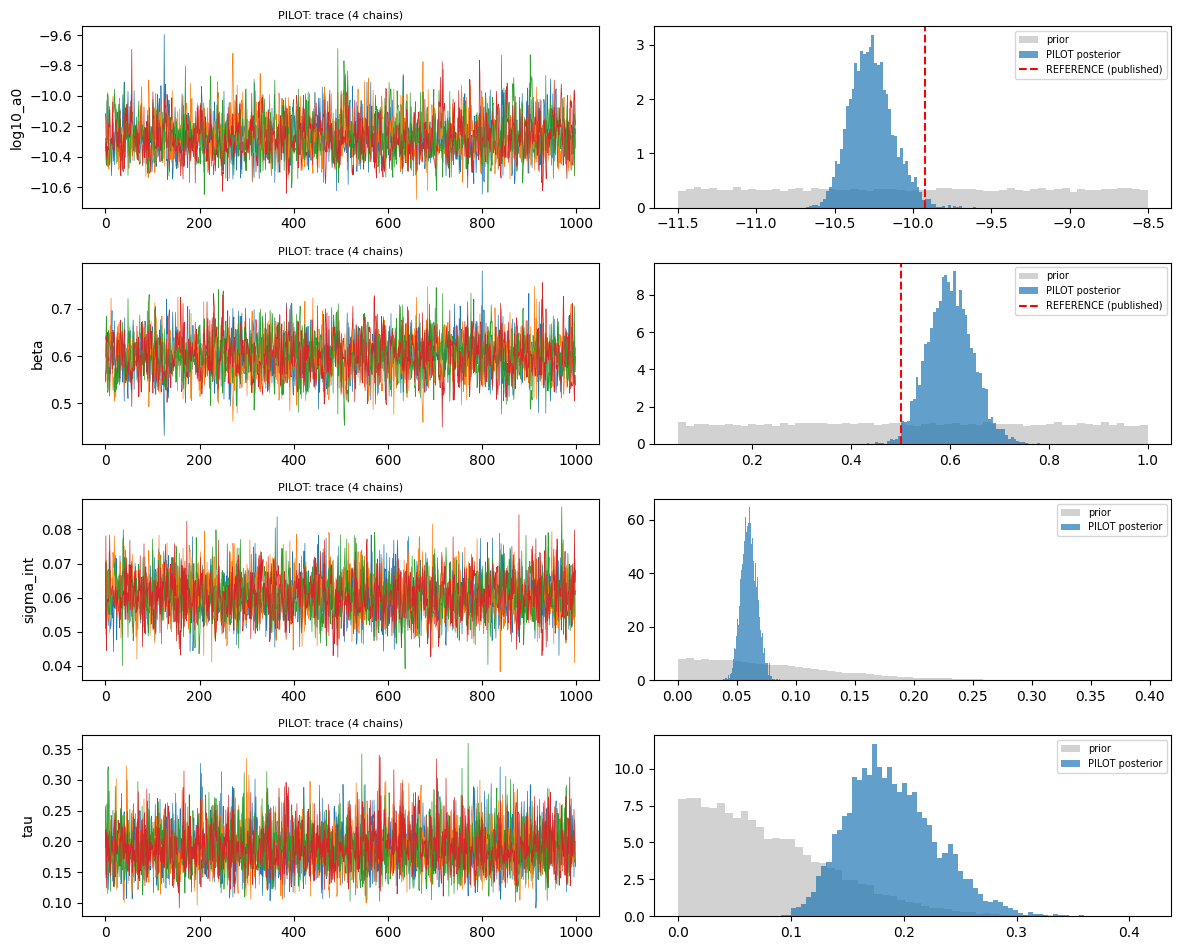

INFO: 03_bayesian_pilot_posterior_correlations.png exists; writing 03_bayesian_pilot_posterior_correlations_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_posterior_correlations.png exists; writing 03_bayesian_pilot_posterior_correlations_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


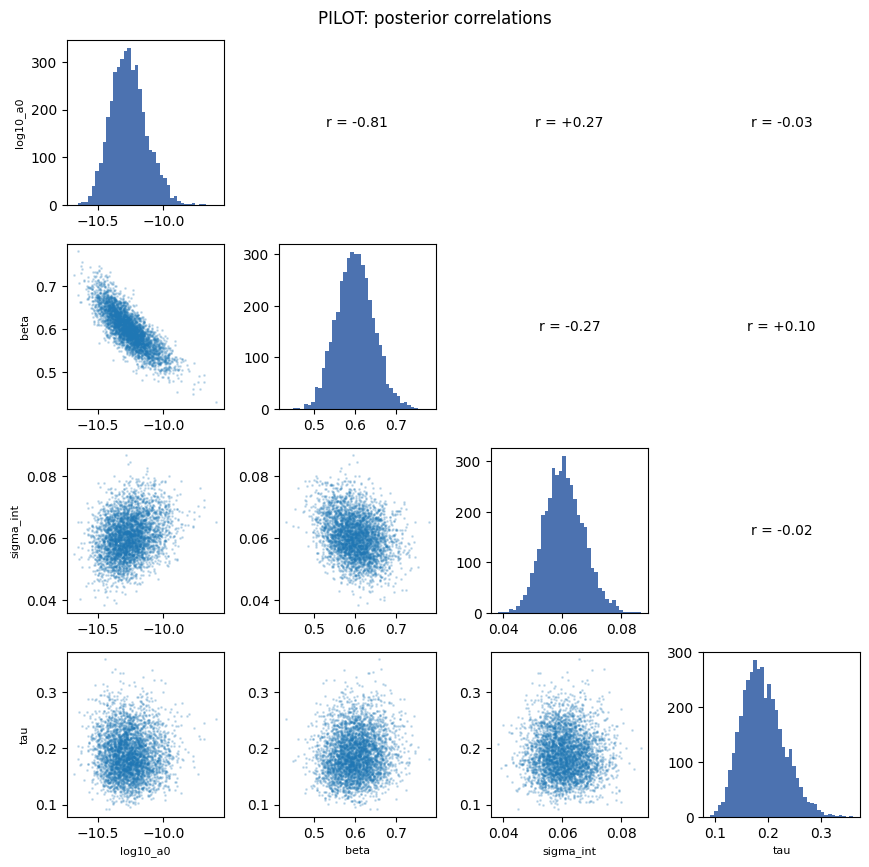

In [32]:
diag_pilot, stats_pilot = diagnostics(mcmc_pilot, data_pilot, PILOT["model"])
post_pilot = posterior_table(mcmc_pilot, "PILOT (validation only)")
display(diag_pilot); print(json.dumps(stats_pilot, indent=1)); display(post_pilot)
PILOT_OK = stats_pilot["converged_by_all_criteria"]
record_check("Pilot", "pilot meets R-hat, ESS and divergence criteria", PILOT_OK,
             f"max R-hat {stats_pilot['max_r_hat_all']:.4f}, min ESS {stats_pilot['min_ess_bulk_all']:.0f}, divergences {stats_pilot['divergences']}", severity="warning")
sigma_tau_corr = float(np.corrcoef(np.asarray(mcmc_pilot.get_samples()["sigma_int"]), np.asarray(mcmc_pilot.get_samples()["tau"]))[0, 1])
print(f"PILOT posterior correlation(sigma_int, tau) = {sigma_tau_corr:+.2f} (identifiability indicator; full study in Notebook 04)")

def plot_traces_and_priors(mcmc, label, fname):
    smp_c = mcmc.get_samples(group_by_chain=True)
    pars = [p for p in GLOBALS if p in smp_c]
    fig, ax = plt.subplots(len(pars), 2, figsize=(12, 2.4 * len(pars)))
    rng_ = np.random.default_rng(1)
    prior_draw = {"log10_a0": rng_.uniform(PRIORS["log10_a0"]["low"], PRIORS["log10_a0"]["high"], 20000),
                  "beta": rng_.uniform(PRIORS["beta"]["low"], PRIORS["beta"]["high"], 20000),
                  "sigma_int": np.abs(rng_.normal(0, PRIORS["sigma_int"]["scale"], 20000)),
                  "tau": np.abs(rng_.normal(0, PRIORS["tau"]["scale"], 20000)),
                  "s": rng_.lognormal(PRIORS["error_inflation_s"]["loc"], PRIORS["error_inflation_s"]["scale"], 20000)}
    refv = {"log10_a0": np.log10(REF["a0"]), "beta": REF["beta"]}
    for r, p in enumerate(pars):
        v = np.asarray(smp_c[p])
        for c in range(v.shape[0]): ax[r, 0].plot(v[c], lw=0.5)
        ax[r, 0].set_ylabel(p); ax[r, 0].set_title(f"{label}: trace ({v.shape[0]} chains)", fontsize=8)
        ax[r, 1].hist(prior_draw[p], bins=60, density=True, alpha=0.35, color="gray", label="prior")
        ax[r, 1].hist(v.ravel(), bins=60, density=True, alpha=0.7, label=f"{label} posterior")
        if p in refv: ax[r, 1].axvline(refv[p], color="r", ls="--", label="REFERENCE (published)")
        ax[r, 1].legend(fontsize=7)
    fig.tight_layout(); out = safe_path(DIRS["graphs"] / fname); fig.savefig(out, dpi=140); plt.show(); return out

def plot_corr(mcmc, label, fname):
    smp = mcmc.get_samples(); pars = [p for p in GLOBALS if p in smp]
    M = np.column_stack([np.asarray(smp[p]) for p in pars]); cm = np.corrcoef(M.T)
    fig, ax = plt.subplots(len(pars), len(pars), figsize=(2.2 * len(pars), 2.2 * len(pars)))
    for a in range(len(pars)):
        for b in range(len(pars)):
            axx = ax[a, b]
            if a == b: axx.hist(M[:, a], bins=40, color="#4C72B0")
            elif a > b: axx.scatter(M[:, b], M[:, a], s=1, alpha=0.2)
            else: axx.text(0.5, 0.5, f"r = {cm[a, b]:+.2f}", ha="center", va="center"); axx.set_axis_off()
            if b == 0: axx.set_ylabel(pars[a], fontsize=8)
            if a == len(pars) - 1: axx.set_xlabel(pars[b], fontsize=8)
    fig.suptitle(f"{label}: posterior correlations"); fig.tight_layout()
    out = safe_path(DIRS["graphs"] / fname); fig.savefig(out, dpi=130); plt.show()
    return pd.DataFrame(cm, index=pars, columns=pars), out

plot_traces_and_priors(mcmc_pilot, "PILOT", "03_bayesian_pilot_traces_priors.png")
corr_pilot, _ = plot_corr(mcmc_pilot, "PILOT", "03_bayesian_pilot_posterior_correlations.png")

In [33]:
# Save pilot results (separate files, labelled PILOT)
ll_pilot = galaxy_loglik_all_draws(mcmc_pilot, data_pilot, PILOT["model"])
record_check("Pilot", "pilot per-galaxy log-likelihoods finite for all draws", bool(np.isfinite(ll_pilot).all()), f"{ll_pilot.shape}")
nc_pilot = save_posterior_netcdf(mcmc_pilot, data_pilot, PILOT["model"], DIRS["posterior"] / "03_bayesian_pilot_posterior.nc", ll_pilot)
post_pilot.to_csv(safe_path(DIRS["tables"] / "03_bayesian_pilot_posterior_summary.csv"), index=False)
diag_pilot.assign(stage="PILOT").to_csv(safe_path(DIRS["diagnostics"] / "03_bayesian_pilot_mcmc_diagnostics.csv"), index=False)
print("Saved pilot posterior:", nc_pilot)

INFO: [PASS] Pilot | pilot per-galaxy log-likelihoods finite for all draws | (4000, 12)


INFO:rar03:[PASS] Pilot | pilot per-galaxy log-likelihoods finite for all draws | (4000, 12)


INFO: 03_bayesian_pilot_posterior.nc exists; writing 03_bayesian_pilot_posterior_20261022T095735Z.nc instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_posterior.nc exists; writing 03_bayesian_pilot_posterior_20261022T095735Z.nc instead (ALLOW_OVERWRITE=False)


INFO: 03_bayesian_pilot_posterior_summary.csv exists; writing 03_bayesian_pilot_posterior_summary_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_posterior_summary.csv exists; writing 03_bayesian_pilot_posterior_summary_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO: 03_bayesian_pilot_mcmc_diagnostics.csv exists; writing 03_bayesian_pilot_mcmc_diagnostics_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_mcmc_diagnostics.csv exists; writing 03_bayesian_pilot_mcmc_diagnostics_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


Saved pilot posterior: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_pilot_posterior_20261022T095735Z.nc


## 13. Full SPARC Inference (Stage B — explicit opt-in)

**Run this only after the pilot meets all criteria.** To enable it, set `FULL_RUN_ENABLED = True` in the cell below. Each model (C, then A, then B) is sampled and **saved as soon as it finishes**, so a later interruption does not lose completed models. Interrupted chains **cannot be resumed** (no sampler-state checkpointing is implemented); an interrupted model must be re-run.

Rough cost: Model C has about 4 + 3×153 + n_bulge parameters on ~3,166 points. Expect tens of minutes to a few hours on a Colab CPU, depending on tree depth. If the session limit is reached, run one model per session by editing `FULL["models"]`.

In [34]:
FULL_RUN_ENABLED = True          # <-- uncomment to run the full 153-galaxy inference
FULL_RESULTS = {}
if not FULL_RUN_ENABLED:
    print("FULL inference NOT run (FULL_RUN_ENABLED = False). No full-sample results exist from this session.")
elif not PILOT_OK:
    print("FULL inference NOT run: the pilot did not meet all convergence criteria. Investigate the pilot first "
          "(or set FORCE_FULL_DESPITE_PILOT = True to override, and report that you did).")
if FULL_RUN_ENABLED and (PILOT_OK or FORCE_FULL_DESPITE_PILOT):
    if not PILOT_OK:
        logger.warning("FULL run forced although the pilot did not meet all criteria; this must be reported.")
    data_full = build_data(include)
    for k, model in enumerate(FULL["models"]):
        logger.info(f"FULL Model {model}: starting ({FULL['chains']} chains, {FULL['warmup']} warmup, {FULL['samples']} samples)")
        mc, tsec, meth = run_mcmc(data_full, model, FULL["chains"], FULL["warmup"], FULL["samples"], SEED + 100 * (k + 1))
        dg, st = diagnostics(mc, data_full, model)
        llg = galaxy_loglik_all_draws(mc, data_full, model)
        nc = save_posterior_netcdf(mc, data_full, model, DIRS["posterior"] / f"03_bayesian_full_model{model}_posterior.nc", llg)
        label = f"FULL Model {model}" + ("" if st["converged_by_all_criteria"] else " (NOT CONVERGED)")
        pt = posterior_table(mc, label)
        pt.to_csv(safe_path(DIRS["tables"] / f"03_bayesian_full_model{model}_posterior_summary.csv"), index=False)
        dg.assign(stage=label).to_csv(safe_path(DIRS["diagnostics"] / f"03_bayesian_full_model{model}_mcmc_diagnostics.csv"), index=False)
        FULL_RESULTS[model] = {"mcmc": mc, "diag": dg, "stats": st, "post": pt, "ll_g": llg, "nc": nc, "seconds": tsec, "chain_method": meth}
        logger.info(f"FULL Model {model}: done in {tsec / 60:.1f} min; converged_by_all_criteria = {st['converged_by_all_criteria']}")
        display(pt); display(dg)

INFO: FULL Model C: starting (4 chains, 1500 warmup, 1000 samples)


INFO:rar03:FULL Model C: starting (4 chains, 1500 warmup, 1000 samples)
sample: 100%|██████████| 2500/2500 [01:24<00:00, 29.73it/s, 31 steps of size 1.67e-01. acc. prob=0.92]


INFO: FULL Model C: done in 5.7 min; converged_by_all_criteria = True


INFO:rar03:FULL Model C: done in 5.7 min; converged_by_all_criteria = True


,stage,parameter,mean,median,sd,ci68_low,ci68_high,ci95_low,ci95_high
0,FULL Model C,log10_a0,-1.004761e+01,-1.004835e+01,2.847060e-02,-1.007559e+01,-1.001892e+01,-1.010224e+01,-9.989501e+00
1,FULL Model C,beta,5.144115e-01,5.144186e-01,6.784963e-03,5.075701e-01,5.211191e-01,5.010592e-01,5.275018e-01
2,FULL Model C,sigma_int,3.557487e-02,3.556919e-02,1.010711e-03,3.457284e-02,3.658477e-02,3.364437e-02,3.753358e-02
3,FULL Model C,tau,1.222659e-01,1.219556e-01,1.094800e-02,1.113175e-01,1.331932e-01,1.018991e-01,1.453344e-01
4,FULL Model C,a0,8.980911e-11,8.946410e-11,5.909018e-12,8.402460e-11,9.573737e-11,7.902444e-11,1.024470e-10
5,FULL Model C,sigma_int_95pct_upper_limit,NaN,3.720406e-02,NaN,NaN,NaN,NaN,NaN
6,FULL Model C,tau_95pct_upper_limit,NaN,1.406001e-01,NaN,NaN,NaN,NaN,NaN


...

INFO:rar03:FULL Model B: starting (4 chains, 1500 warmup, 1000 samples)
sample: 100%|██████████| 2500/2500 [00:20<00:00, 123.57it/s, 3 steps of size 3.83e-01. acc. prob=0.94]


INFO: FULL Model B: done in 1.4 min; converged_by_all_criteria = True


INFO:rar03:FULL Model B: done in 1.4 min; converged_by_all_criteria = True


,stage,parameter,mean,median,sd,ci68_low,ci68_high,ci95_low,ci95_high
0,FULL Model B,log10_a0,-9.795220e+00,-9.795616e+00,2.657920e-02,-9.820867e+00,-9.769321e+00,-9.847124e+00,-9.742102e+00
1,FULL Model B,beta,4.769222e-01,4.767756e-01,5.291253e-03,4.717387e-01,4.821322e-01,4.664792e-01,4.874289e-01
2,FULL Model B,sigma_int,4.598978e-02,4.595157e-02,1.394106e-03,4.458028e-02,4.742038e-02,4.332701e-02,4.872690e-02
3,FULL Model B,tau,1.473918e-01,1.471084e-01,9.579718e-03,1.378023e-01,1.567845e-01,1.297993e-01,1.670534e-01
4,FULL Model B,s,1.460177e+00,1.459215e+00,4.090959e-02,1.419336e+00,1.500314e+00,1.383754e+00,1.544892e+00
5,FULL Model B,a0,1.605441e-10,1.600973e-10,9.858926e-12,1.510544e-10,1.700901e-10,1.421922e-10,1.810916e-10
6,FULL Model B,sigma_int_95pct_upper_limit,NaN,4.826028e-02,NaN,NaN,NaN,NaN,NaN
7,FULL Model B,tau_95pct_upper_limit,NaN,1.634919e-01,NaN,NaN,NaN,NaN,NaN


,parameter,n_elements,max_r_hat,min_ess_bulk,median_ess
0,beta,1,1.000037,2203.712563,2203.712563
1,log10_a0,1,1.000197,2012.096355,2012.096355
2,s,1,0.999623,2588.220708,2588.220708
3,sigma_int,1,1.000009,2482.632024,2482.632024
4,tau,1,0.999597,2954.906277,2954.906277


## 14. Posterior Predictive Checks

Replicated data y_rep are drawn using each posterior draw's nuisance values, f(x), a conditional draw of δ_i, and the diagonal noise. Reported quantities:

* coverage of the 68% and 95% predictive intervals (point level and per galaxy)
* standardised residuals compared with N(0, 1)
* the RAR with the posterior band, shown next to the REFERENCE curve

PPCs are run for the pilot and, if present, the full Model C.

INFO: 03_bayesian_pilot_ppc.png exists; writing 03_bayesian_pilot_ppc_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_ppc.png exists; writing 03_bayesian_pilot_ppc_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


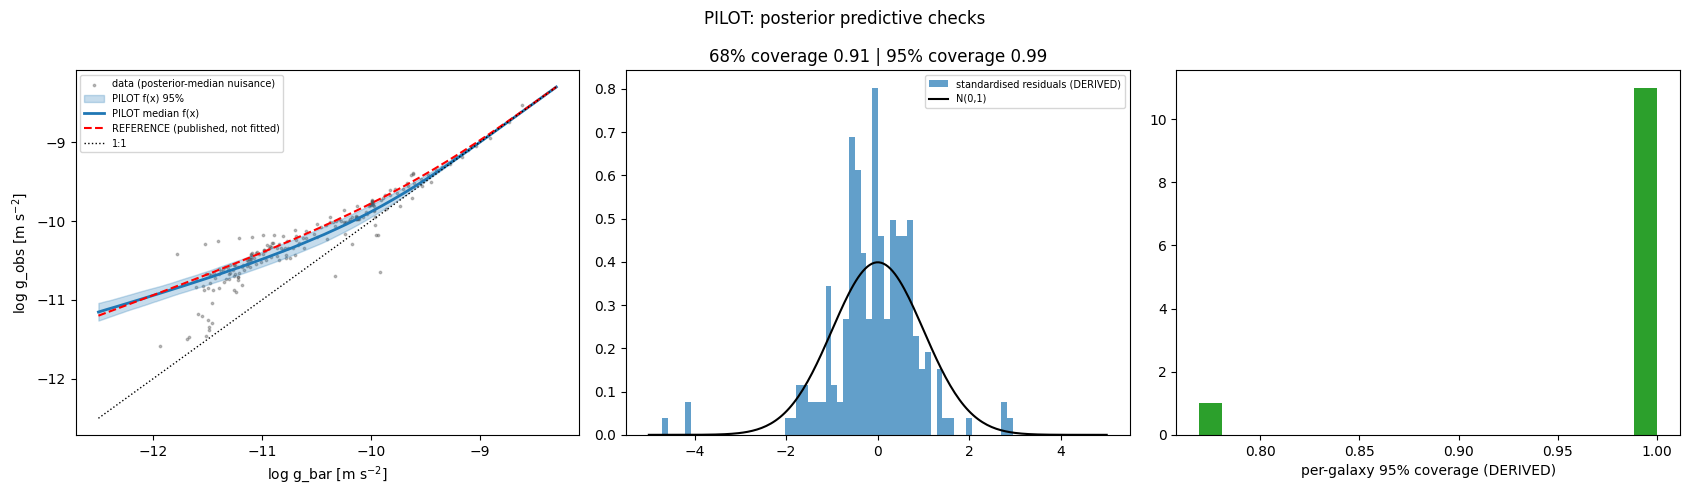

INFO: 03_bayesian_pilot_ppc_per_galaxy.csv exists; writing 03_bayesian_pilot_ppc_per_galaxy_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_ppc_per_galaxy.csv exists; writing 03_bayesian_pilot_ppc_per_galaxy_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


PILOT PPC: {'coverage68': 0.9073170731707317, 'coverage95': 0.9853658536585366, 'z_mean': -0.07536063222363762, 'z_sd': 0.9516441064406009, 'n_points': 205}


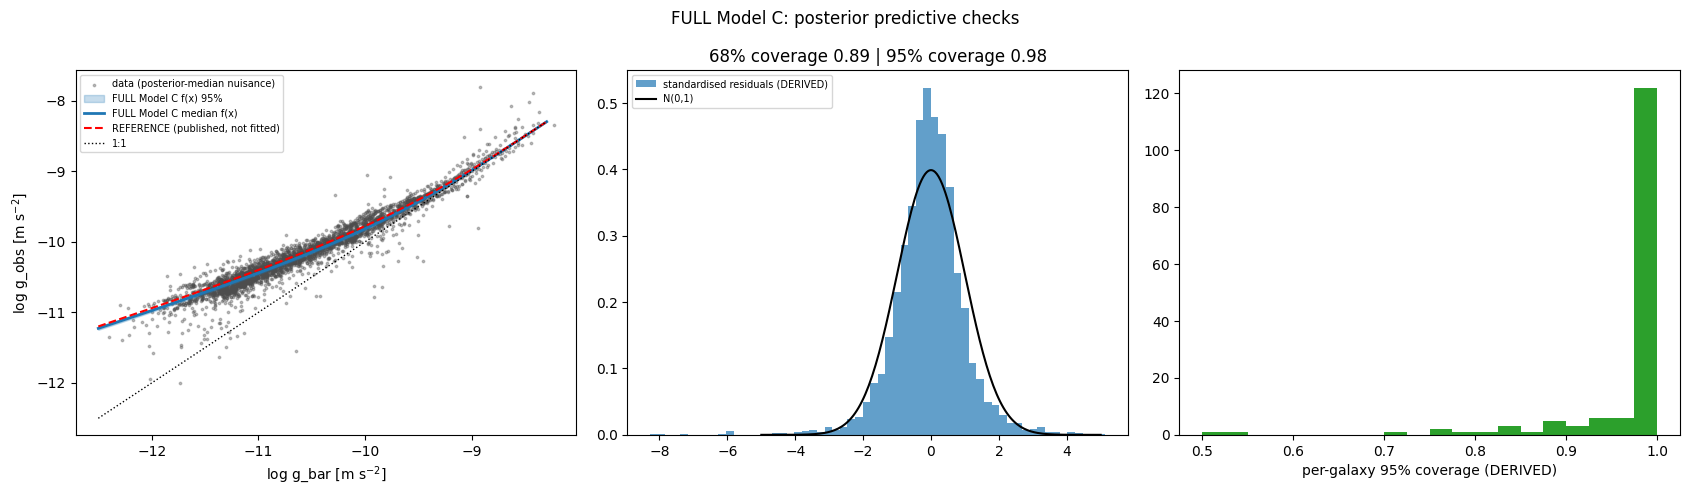

FULL Model C PPC: {'coverage68': 0.8934892541087232, 'coverage95': 0.9756637168141593, 'z_mean': -0.055516517569415426, 'z_sd': 1.0445618648546344, 'n_points': 3164}


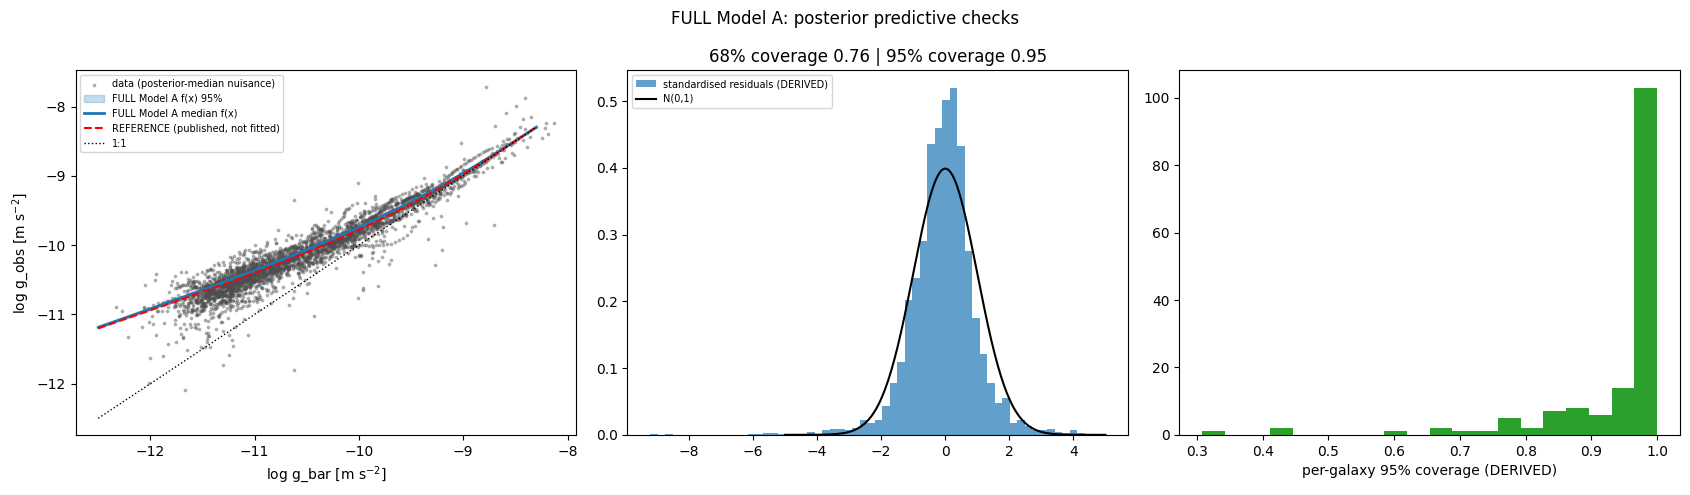

FULL Model A PPC: {'coverage68': 0.7635903919089759, 'coverage95': 0.9487989886219975, 'z_mean': -0.05196217136582077, 'z_sd': 1.0315013126033181, 'n_points': 3164}


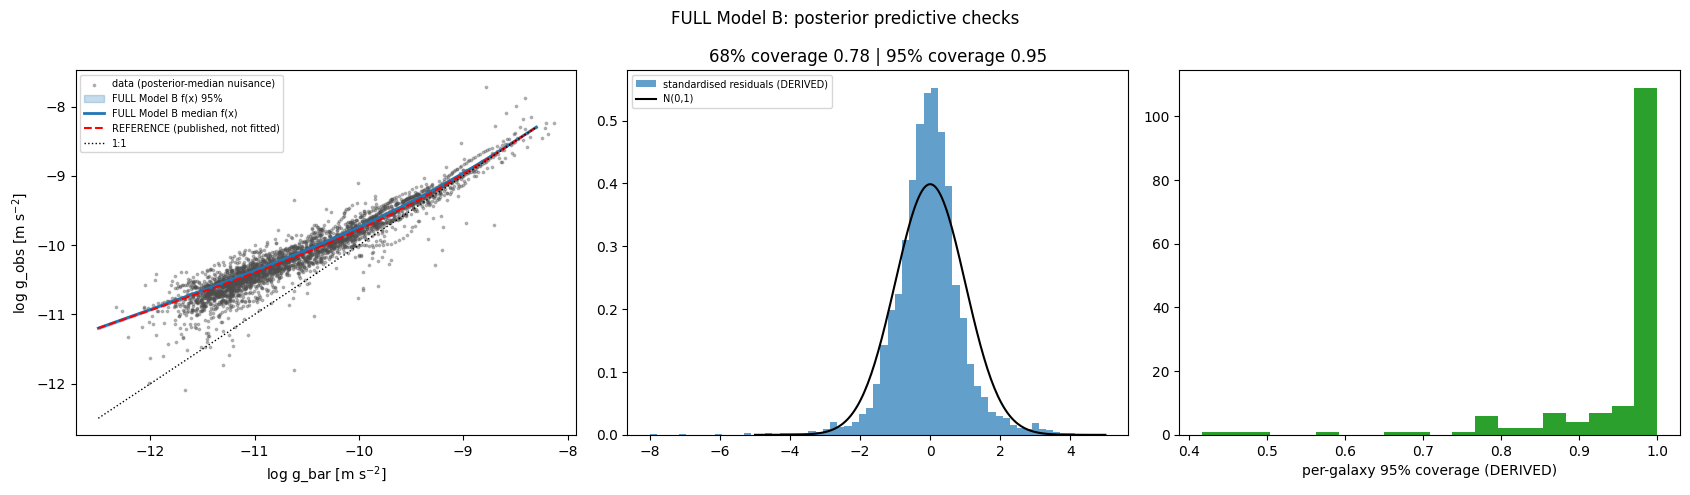

FULL Model B PPC: {'coverage68': 0.7816055625790139, 'coverage95': 0.9516434892541087, 'z_mean': -0.05801407421869686, 'z_sd': 0.9740397080785462, 'n_points': 3164}
INFO: 03_bayesian_pilot_nuisance.png exists; writing 03_bayesian_pilot_nuisance_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_nuisance.png exists; writing 03_bayesian_pilot_nuisance_20261022T095735Z.png instead (ALLOW_OVERWRITE=False)


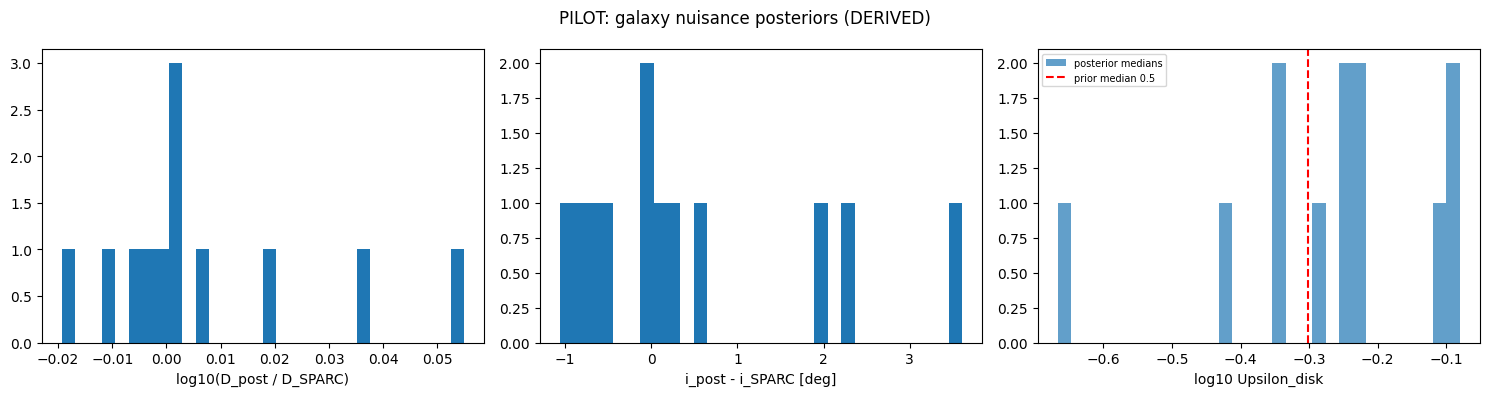

INFO: 03_bayesian_pilot_nuisance_posteriors.csv exists; writing 03_bayesian_pilot_nuisance_posteriors_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_pilot_nuisance_posteriors.csv exists; writing 03_bayesian_pilot_nuisance_posteriors_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


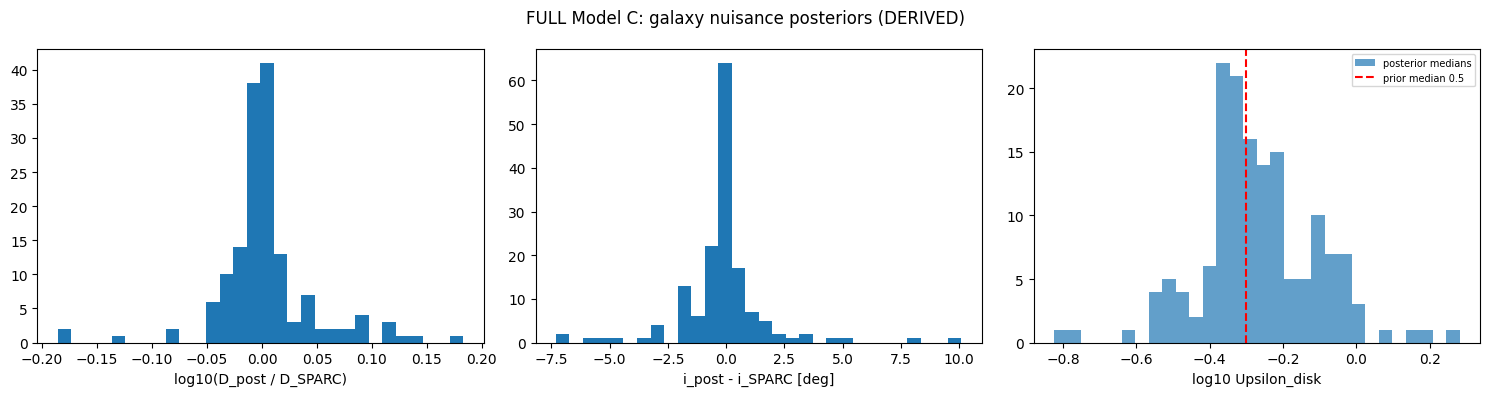

In [35]:
def ppc(mcmc, data, model, label, tag):
    pr = posterior_draw_products(mcmc, data, model, PPC_DRAWS, SEED)
    lo68, hi68 = np.percentile(pr["yrep"], [16, 84], axis=0); lo95, hi95 = np.percentile(pr["yrep"], [2.5, 97.5], axis=0)
    yobs = np.median(pr["y"], axis=0); xmed = np.median(pr["x"], axis=0)
    cov68 = float(np.mean((yobs >= lo68) & (yobs <= hi68))); cov95 = float(np.mean((yobs >= lo95) & (yobs <= hi95)))
    z = np.median((pr["y"] - pr["mu"] - pr["delta"][:, np.asarray(data["idx"])]) / pr["sd"], axis=0)
    idx = np.asarray(data["idx"]); gal_names = gtab.galaxy.to_numpy()[data["gal_ids"]]
    per_gal = pd.DataFrame({"galaxy": gal_names[idx], "in95": (yobs >= lo95) & (yobs <= hi95), "z": z}).groupby("galaxy").agg(
        n=("z", "size"), coverage95=("in95", "mean"), mean_z=("z", "mean"), rms_z=("z", lambda s: float(np.sqrt(np.mean(s ** 2)))))
    per_gal["delta_median"] = np.median(pr["delta"], axis=0)
    smp = mcmc.get_samples(); lg = np.linspace(-12.5, -8.3, 200)
    sel = pr["draw_index"]
    curves = np.stack([np.asarray(f_rar(lg, smp["log10_a0"][i], smp["beta"][i])) for i in sel])
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    ax[0].scatter(xmed, yobs, s=3, alpha=0.35, color="0.3", label="data (posterior-median nuisance)")
    ax[0].fill_between(lg, *np.percentile(curves, [2.5, 97.5], axis=0), color="C0", alpha=0.25, label=f"{label} f(x) 95%")
    ax[0].plot(lg, np.median(curves, axis=0), "C0-", lw=2, label=f"{label} median f(x)")
    ax[0].plot(lg, np.asarray(f_rar(lg, np.log10(REF["a0"]), REF["beta"])), "r--", lw=1.5, label="REFERENCE (published, not fitted)")
    ax[0].plot(lg, lg, "k:", lw=1, label="1:1")
    ax[0].set_xlabel("log g_bar [m s$^{-2}$]"); ax[0].set_ylabel("log g_obs [m s$^{-2}$]"); ax[0].legend(fontsize=7)
    ax[1].hist(z, bins=60, density=True, alpha=0.7, label="standardised residuals (DERIVED)")
    zz = np.linspace(-5, 5, 200); ax[1].plot(zz, sst.norm.pdf(zz), "k-", label="N(0,1)"); ax[1].legend(fontsize=7)
    ax[1].set_title(f"68% coverage {cov68:.2f} | 95% coverage {cov95:.2f}")
    ax[2].hist(per_gal.coverage95, bins=20, color="C2"); ax[2].set_xlabel("per-galaxy 95% coverage (DERIVED)")
    fig.suptitle(f"{label}: posterior predictive checks"); fig.tight_layout()
    fig.savefig(safe_path(DIRS["graphs"] / f"03_bayesian_{tag}_ppc.png"), dpi=140); plt.show()
    per_gal.to_csv(safe_path(DIRS["diagnostics"] / f"03_bayesian_{tag}_ppc_per_galaxy.csv"))
    return {"coverage68": cov68, "coverage95": cov95, "z_mean": float(np.mean(z)), "z_sd": float(np.std(z)), "n_points": int(len(z))}

ppc_pilot = ppc(mcmc_pilot, data_pilot, PILOT["model"], "PILOT", "pilot")
print("PILOT PPC:", ppc_pilot)
ppc_full = {}
for model, res in FULL_RESULTS.items():
    ppc_full[model] = ppc(res["mcmc"], build_data(include), model, f"FULL Model {model}", f"full_model{model}")
    print(f"FULL Model {model} PPC:", ppc_full[model])

# Galaxy-level nuisance diagnostics (Model C fits)
def nuisance_plot(mcmc, data, label, tag):
    smp = mcmc.get_samples(); names = gtab.galaxy.to_numpy()[data["gal_ids"]]
    tab = pd.DataFrame({"galaxy": names, "D_ratio_median": np.median(np.asarray(smp["D"]) / np.asarray(data["D0"]), axis=0),
                        "inc_shift_median_deg": np.median(np.asarray(smp["inc"]) - np.asarray(data["I0"]), axis=0),
                        "ups_disk_median": np.median(np.asarray(smp["ups_disk"]), axis=0)})
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].hist(np.log10(tab.D_ratio_median), bins=30); ax[0].set_xlabel("log10(D_post / D_SPARC)")
    ax[1].hist(tab.inc_shift_median_deg, bins=30); ax[1].set_xlabel("i_post - i_SPARC [deg]")
    ax[2].hist(np.log10(tab.ups_disk_median), bins=30, alpha=0.7, label="posterior medians")
    ax[2].axvline(np.log10(0.5), color="r", ls="--", label="prior median 0.5"); ax[2].set_xlabel("log10 Upsilon_disk"); ax[2].legend(fontsize=7)
    fig.suptitle(f"{label}: galaxy nuisance posteriors (DERIVED)"); fig.tight_layout()
    fig.savefig(safe_path(DIRS["graphs"] / f"03_bayesian_{tag}_nuisance.png"), dpi=140); plt.show()
    tab.to_csv(safe_path(DIRS["diagnostics"] / f"03_bayesian_{tag}_nuisance_posteriors.csv"), index=False)
nuisance_plot(mcmc_pilot, data_pilot, "PILOT", "pilot")
if "C" in FULL_RESULTS:
    nuisance_plot(FULL_RESULTS["C"]["mcmc"], build_data(include), "FULL Model C", "full_modelC")

## 15. Independent-Error Model Comparison (ladder rungs a–c)

All three models use the **same points** and the same RAR and scatter structure. They differ only in how measurement uncertainties are treated: A uses fixed catalogue nuisance values and published errors; B adds a fitted error-inflation factor s; C samples D, i and Υ★. Each is compared by galaxy-level PSIS-LOO (elpd, leaving out one galaxy at a time) and by its posterior for a₀, β, σ_int and τ. Rows are filled only for models that actually ran. The rows report whether σ_int ≈ 0.034 dex survives (proposal Sec. 4.4), but a numerical match to Desmond (2023) would not mean the analyses agree: the likelihoods, priors, samples and nuisance treatments differ.

In [36]:
comp_rows = []
def comp_row(stage, model, mcmc, ll_g, stats):
    elpd, k = psis_loo(ll_g)
    smp = mcmc.get_samples()
    lppd = np.logaddexp.reduce(ll_g, axis=0) - np.log(ll_g.shape[0])
    row = {"stage": stage, "model": model, "n_galaxies": ll_g.shape[1], "elpd_loo_galaxy": float(elpd.sum()),
           "elpd_loo_se": float(np.sqrt(ll_g.shape[1] * np.var(elpd))), "p_loo": float(lppd.sum() - elpd.sum()),
           "n_pareto_k_gt_0.7": int((k > 0.7).sum()), "converged_by_all_criteria": stats["converged_by_all_criteria"],
           "max_r_hat": stats["max_r_hat_all"], "min_ess_bulk": stats["min_ess_bulk_all"], "divergences": stats["divergences"]}
    for p in ("log10_a0", "beta", "sigma_int", "tau", "s"):
        if p in smp:
            q = np.percentile(np.asarray(smp[p]), [16, 50, 84]); row[f"{p}_median"] = q[1]; row[f"{p}_ci68"] = f"[{q[0]:.4f}, {q[2]:.4f}]"
    if "sigma_int" in smp:
        v = np.asarray(smp["sigma_int"]); row["P(sigma_int < 0.034 dex)"] = float(np.mean(v < 0.034)); row["sigma_int_95pct_upper"] = float(np.percentile(v, 95))
    return row

comp_rows.append(comp_row("PILOT (validation only)", PILOT["model"], mcmc_pilot, ll_pilot, stats_pilot))
for model in ("A", "B", "C"):
    if model in FULL_RESULTS:
        r = FULL_RESULTS[model]; comp_rows.append(comp_row("FULL", model, r["mcmc"], r["ll_g"], r["stats"]))
    else:
        comp_rows.append({"stage": "FULL", "model": model, "status": "NOT RUN in this session (no result exists)"})
model_comparison = pd.DataFrame(comp_rows)
display(model_comparison)

,stage,model,n_galaxies,elpd_loo_galaxy,elpd_loo_se,p_loo,n_pareto_k_gt_0.7,converged_by_all_criteria,max_r_hat,min_ess_bulk,...,beta_median,beta_ci68,sigma_int_median,sigma_int_ci68,tau_median,tau_ci68,P(sigma_int < 0.034 dex),sigma_int_95pct_upper,s_median,s_ci68
0,PILOT (validation only),C,12,135.761034,78.990560,58.684227,5,True,1.002144,2553.916447,...,0.599839,"[0.5556, 0.6459]",0.060355,"[0.0539, 0.0674]",0.186125,"[0.1512, 0.2304]",0.00,0.071893,NaN,NaN
1,FULL,A,153,3084.192629,342.265888,47.431458,3,True,1.002565,1913.158616,...,0.483261,"[0.4776, 0.4886]",0.057298,"[0.0562, 0.0584]",0.155636,"[0.1458, 0.1660]",0.00,0.059196,NaN,NaN
2,FULL,B,153,3151.837121,350.150088,64.228407,4,True,1.000197,2012.096355,...,0.476776,"[0.4717, 0.4821]",0.045952,"[0.0446, 0.0474]",0.147108,"[0.1378, 0.1568]",0.00,0.048260,1.459215,"[1.4193, 1.5003]"
3,FULL,C,153,3661.801975,406.849916,379.460001,88,True,1.001391,2961.645013,...,0.514419,"[0.5076, 0.5211]",0.035569,"[0.0346, 0.0366]",0.121956,"[0.1113, 0.1332]",0.06,0.037204,NaN,NaN


## 16. Results Export and Reproducibility

In [37]:
prior_summary.to_csv(safe_path(DIRS["tables"] / "03_bayesian_prior_summary.csv"), index=False)
model_comparison.to_csv(safe_path(DIRS["tables"] / "03_bayesian_model_comparison.csv"), index=False)
pos_table.to_csv(safe_path(DIRS["processed"] / "03_bayesian_positivity_rule_points.csv"), index=False)
diag_all = [diag_pilot.assign(stage="PILOT")] + [r["diag"].assign(stage=f"FULL Model {m}") for m, r in FULL_RESULTS.items()]
pd.concat(diag_all).to_csv(safe_path(DIRS["diagnostics"] / "03_bayesian_mcmc_diagnostics.csv"), index=False)
if FULL_RESULTS:
    pd.concat([r["post"] for r in FULL_RESULTS.values()]).to_csv(safe_path(DIRS["tables"] / "03_bayesian_full_posterior_summary.csv"), index=False)
sampler_config = {
    "run_id": RUN_ID, "created_utc": RUN_TIMESTAMP, "versions": VERSIONS, "seed": SEED,
    "target_accept": TARGET_ACCEPT, "max_tree_depth": MAX_TREE_DEPTH, "pilot": {**PILOT, "galaxies": list(gtab.galaxy.to_numpy()[pilot_gals]),
    "seconds": t_pilot, "chain_method": method_pilot, "stats": stats_pilot}, "full_run_enabled": FULL_RUN_ENABLED,
    "full": {**FULL, "completed_models": {m: {"seconds": r["seconds"], "stats": r["stats"], "netcdf": str(r["nc"]), "chain_method": r["chain_method"]}
                                           for m, r in FULL_RESULTS.items()}},
    "convergence_criteria": {"r_hat_max": RHAT_MAX, "ess_bulk_min": ESS_BULK_MIN, "divergences_max": DIVERGENCES_MAX},
    "priors": PRIORS, "sigma_x_log_gbar": SIGMA_X_LOG_GBAR, "reference_values_not_fitted": REF,
    "positivity_rule": {"P_prior_min": POS_PRIOR_PROB_MIN, "mc_draws": POS_MC_DRAWS, "n_points_included": int(include.sum()),
                        "excluded_points": [list(x) for x in sorted(rule_excl_keys)]},
    "input_checksums": {p.name: sha256_of(p) for p in (NB02["points"], NB02["galaxies"], NB02["npz"])},
    "resume_note": "No sampler-state checkpointing: interrupted chains cannot be resumed.",
}
cfg_path = safe_path(DIRS["models"] / "03_bayesian_sampler_config.json"); cfg_path.write_text(json.dumps(sampler_config, indent=2, default=str))
model_spec = {"likelihood": "y_ij = f(x_ij; a0, beta) + delta_i + eps_ij; delta_i ~ N(0, tau^2) marginalised (Sherman-Morrison); "
                            "C_i = diag(s^2 sigma_V^2 + f'^2 sigma_x^2 + sigma_int^2) + tau^2 11^T",
              "models": {"A": "fixed catalogue D, i; Upsilon = 0.5/0.7; s = 1", "B": "as A with free s", "C": "D, i, Upsilon sampled; s = 1"},
              "nuisance_scaling": "R ∝ D, V_k ∝ sqrt(D), V_obs and errV ∝ sin(i0)/sin(i); Vgas signed (Vgas|Vgas|)",
              "excluded_from_this_notebook": ["GP covariance J K J", "population terms", "survey offsets", "injection-recovery", "5-fold CV"]}
(safe_path(DIRS["models"] / "03_bayesian_model_specification.json")).write_text(json.dumps(model_spec, indent=2))
pd.DataFrame(CHECKS).to_csv(safe_path(DIRS["processed"] / "03_bayesian_integrity_checks.csv"), index=False)
print("Saved configuration, model specification, tables and checks.")

INFO: 03_bayesian_prior_summary.csv exists; writing 03_bayesian_prior_summary_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_prior_summary.csv exists; writing 03_bayesian_prior_summary_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO: 03_bayesian_model_comparison.csv exists; writing 03_bayesian_model_comparison_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_model_comparison.csv exists; writing 03_bayesian_model_comparison_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO: 03_bayesian_positivity_rule_points.csv exists; writing 03_bayesian_positivity_rule_points_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


...

INFO: 03_bayesian_model_specification.json exists; writing 03_bayesian_model_specification_20261022T095735Z.json instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_model_specification.json exists; writing 03_bayesian_model_specification_20261022T095735Z.json instead (ALLOW_OVERWRITE=False)


INFO: 03_bayesian_integrity_checks.csv exists; writing 03_bayesian_integrity_checks_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_bayesian_integrity_checks.csv exists; writing 03_bayesian_integrity_checks_20261022T095735Z.csv instead (ALLOW_OVERWRITE=False)


Saved configuration, model specification, tables and checks.


## 17. Final Notebook 03 Summary

In [38]:
def fmt_post(pt):
    keep = pt[pt.parameter.isin(["log10_a0", "beta", "sigma_int", "tau", "s"])]
    return "\n".join(f"| {r.parameter} | {r.median:.4f} | [{r.ci68_low:.4f}, {r.ci68_high:.4f}] | [{r.ci95_low:.4f}, {r.ci95_high:.4f}] |" for r in keep.itertuples())
full_section = "**FULL inference was not run in this session; no full-sample results exist.**" if not FULL_RESULTS else "\n\n".join(
    f"### FULL Model {m} — {'converged by all criteria' if r['stats']['converged_by_all_criteria'] else 'NOT CONVERGED: do not interpret'}\n"
    f"max R-hat {r['stats']['max_r_hat_all']:.4f}, min bulk ESS {r['stats']['min_ess_bulk_all']:.0f}, divergences {r['stats']['divergences']}, "
    f"time {r['seconds']/60:.1f} min\n\n| parameter | median | 68% CI | 95% CI |\n|---|---|---|---|\n{fmt_post(r['post'])}" for m, r in FULL_RESULTS.items())
checks_df = pd.DataFrame(CHECKS)
report = f'''# Notebook 03 — Hierarchical Bayesian Inference Report

*Run {RUN_ID} ({RUN_TIMESTAMP} UTC). Generated by `03_Hierarchical_Bayesian_Model.ipynb`; this file exists only if the notebook ran.*

## Scope
SPARC only (153 eligible galaxies; cross-survey gate not passed). Independent-error model of proposal Secs. 4.1–4.2 with ladder rungs (a)–(c). No GP covariance, population terms, injection–recovery or cross-validation.

## Data and positivity rule
Points in the likelihood: {int(include.sum())} of {len(include)}. Excluded by the fixed positivity rule (P_prior(g_bar > 0) < {POS_PRIOR_PROB_MIN}): {sorted(rule_excl_keys)}.
Sigma_x = 0: SPARC provides no uncertainties for the baryonic components (documented omission; the term is kept in the code).

## PILOT (validation only — not a scientific result)
Galaxies: {data_pilot["G"]}; converged by all criteria: **{PILOT_OK}** (max R-hat {stats_pilot["max_r_hat_all"]:.4f}, min ESS {stats_pilot["min_ess_bulk_all"]:.0f}, divergences {stats_pilot["divergences"]}).
PPC coverage 68% / 95%: {ppc_pilot["coverage68"]:.2f} / {ppc_pilot["coverage95"]:.2f}. Correlation(sigma_int, tau): {sigma_tau_corr:+.2f}.

| parameter | median | 68% CI | 95% CI |
|---|---|---|---|
{fmt_post(post_pilot)}

## FULL inference
{full_section}

## Interpretation limits
* REFERENCE values (a0 = 1.2e-10 m s^-2, beta = 0.5) are published values shown for comparison only.
* sigma_int and tau may trade off; their separation from correlated noise is tested in Notebook 04 and in injection–recovery.
* Agreement or disagreement of sigma_int with Desmond (2023) cannot be read as reproduction or refutation without matching likelihood, priors, sample and nuisance treatment.

## Checks
{len(checks_df)} checks: {int((checks_df.status=="FAIL").sum())} FAIL, {int((checks_df.status=="WARN").sum())} WARN.
'''
rep_path = safe_path(DIRS["tables"] / "03_Bayesian_Inference_Report.md"); rep_path.write_text(report, encoding="utf-8")

print("=" * 72); print("NOTEBOOK 03 SUMMARY"); print("=" * 72)
print(f"Points in likelihood: {int(include.sum())} / {len(include)}; galaxies: {G}")
print(f"PILOT ({data_pilot['G']} galaxies): converged by all criteria = {PILOT_OK} | max R-hat {stats_pilot['max_r_hat_all']:.4f} | "
      f"min ESS {stats_pilot['min_ess_bulk_all']:.0f} | divergences {stats_pilot['divergences']}  [validation only]")
if FULL_RESULTS:
    for m, r in FULL_RESULTS.items():
        print(f"FULL Model {m}: converged by all criteria = {r['stats']['converged_by_all_criteria']} | max R-hat {r['stats']['max_r_hat_all']:.4f} | "
              f"min ESS {r['stats']['min_ess_bulk_all']:.0f} | divergences {r['stats']['divergences']}")
else:
    print("FULL inference: NOT RUN (enable in Section 13 after a successful pilot)")
print(f"Checks: {len(checks_df)} | FAIL {int((checks_df.status=='FAIL').sum())} | WARN {int((checks_df.status=='WARN').sum())}")
print("Outputs:"); [print("   ", d) for d in DIRS.values()]; print("    report:", rep_path); print("    log:", LOG_PATH)

INFO: 03_Bayesian_Inference_Report.md exists; writing 03_Bayesian_Inference_Report_20261022T095735Z.md instead (ALLOW_OVERWRITE=False)


INFO:rar03:03_Bayesian_Inference_Report.md exists; writing 03_Bayesian_Inference_Report_20261022T095735Z.md instead (ALLOW_OVERWRITE=False)


NOTEBOOK 03 SUMMARY
Points in likelihood: 3164 / 3168; galaxies: 153
PILOT (12 galaxies): converged by all criteria = True | max R-hat 1.0021 | min ESS 2554 | divergences 0  [validation only]
FULL Model C: converged by all criteria = True | max R-hat 1.0014 | min ESS 2962 | divergences 0
FULL Model A: converged by all criteria = True | max R-hat 1.0026 | min ESS 1913 | divergences 0
FULL Model B: converged by all criteria = True | max R-hat 1.0002 | min ESS 2012 | divergences 0
Checks: 43 | FAIL 0 | WARN 1
Outputs:
    /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data
    /content/drive/MyDrive/RAR_Universality_Research/04_Trained_Models
    /content/drive/MyDrive/RAR_Universality_Research/05_Results/Tables
    /content/drive/MyDrive/RAR_Universality_Research/05_Results/Graphs
    /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples
    /content/drive/MyDrive/RAR_Universality_Research/05_Results/Diagnostics
    /content/drive/MyDrive/RAR_Univer